# Análisis forense del incidente en el portal de TechCorp

**Caso:** el lunes 9 de noviembre de 2026, el equipo de TI encontró un archivo PHP desconocido en la carpeta de fotos de perfil del portal interno (`/uploads/avatars/`). El portal corre **PHP 8.3.30**, versión anterior al parche 8.3.36 que corrige **PHP2Shell (CVE-2026-109618 / CVE-2026-109619)**, una falla que permite ejecutar código de forma remota y sin autenticación. Se pide reconstruir lo ocurrido a partir de los registros de la última semana.

**Preguntas forenses**

| # | Pregunta |
|---|---|
| 1 | **¿Cuándo?** Inicio, explotación, exfiltración y fin del ataque |
| 2 | **¿Dónde?** Servidor, ruta de entrada y artefactos en disco |
| 3 | **¿Cómo?** Vector de entrada y técnicas usadas |
| 4 | **¿Quién?** IP de origen, herramientas (User-Agent) |
| 5 | **¿Qué?** Registros de clientes y empleados consultados y extraídos |

**Fuentes de evidencia** (montadas en **solo lectura** en `/evidencia/logs`):

| Fuente | Archivo | Qué registra |
|---|---|---|
| Servidor web (Apache) | `web/access.jsonl` | Cada petición HTTP: IP, URI, código, bytes, User-Agent, `request_id` |
| Aplicación (PHP) | `app/app.jsonl` | Inicios de sesión, errores, accesos denegados, caídas de procesos |
| Base de datos (auditoría) | `db/audit.jsonl` | Cada sentencia SQL: usuario de BD, filas devueltas e id de los registros |
| Integridad de archivos (FIM) | `fim/fim.jsonl` | Archivos creados o modificados en el servidor web |

**Metodología:** NIST SP 800-86 e ISO/IEC 27037 (identificación → preservación → análisis → presentación). El motor de análisis es **DuckDB** (SQL columnar sobre JSON y Parquet). Procesa cientos de miles de eventos en un portátil sin clúster, y sus consultas se trasladan casi sin cambios a Spark SQL.

> Laboratorio académico: los datos son ficticios y el ataque es una simulación controlada (no se usó ningún exploit real).

## 0. Configuración del entorno

In [1]:
import base64, hashlib, ipaddress, json, os, re, time
from pathlib import Path
from urllib.parse import parse_qs

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from IPython.display import Markdown, display
import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)

BASE = Path.cwd().parent                                     # .../analisis
EVIDENCIA = Path(os.environ.get('EVIDENCIA') or BASE.parent / 'logs')
CONTEXTO = BASE / 'contexto'
SALIDA = BASE / 'salida'
FIG, LAKE = SALIDA / 'figuras', SALIDA / 'lake'
SOLUCIONARIO = next((p for p in [BASE / 'solucionario', BASE.parent / 'simulacion'] if p.exists()), None)
for p in (FIG, LAKE):
    p.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_colwidth', 110)
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 30)
con = duckdb.connect()            # base de datos analítica en memoria

# --- Estilo de los gráficos (sobrio, apto para diapositivas) ---------------------------
TINTA, TINTA2, TENUE = '#0b0b0b', '#52514e', '#898781'
REJILLA, EJE, FONDO = '#e1e0d9', '#c3c2b7', '#fcfcfb'
AZUL, CRITICO, GRIS = '#2a78d6', '#d03b3b', '#b5b3aa'
RAMPA_AZUL = LinearSegmentedColormap.from_list('azul', ['#cde2fb', '#86b6ef', '#3987e5', '#256abf', '#184f95', '#0d366b'])
plt.rcParams.update({
    'figure.facecolor': FONDO, 'axes.facecolor': FONDO, 'savefig.facecolor': FONDO,
    'axes.edgecolor': EJE, 'axes.labelcolor': TINTA2, 'axes.titlecolor': TINTA, 'text.color': TINTA,
    'xtick.color': EJE, 'ytick.color': EJE, 'xtick.labelcolor': TINTA2, 'ytick.labelcolor': TINTA2,
    'axes.grid': True, 'grid.color': REJILLA, 'grid.linewidth': 0.6, 'grid.linestyle': '-',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.axisbelow': True,
    'axes.titlesize': 13, 'axes.titleweight': 'semibold', 'axes.titlelocation': 'left', 'axes.titlepad': 12,
    'font.family': 'DejaVu Sans', 'font.size': 10.5, 'legend.frameon': False,
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight', 'lines.linewidth': 2,
})

def guardar(fig, nombre):
    fig.savefig(FIG / f'{nombre}.png')
    plt.show()

def num(x, dec=0):
    '''Número en formato español: 12.345,67'''
    return f'{x:,.{dec}f}'.replace(',', '_').replace('.', ',').replace('_', '.')

def mb(b):
    return num(b / 1_048_576, 2) + ' MB'

def formato_dias(ax):
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: (lambda d: f"{DIAS_ES[d.weekday()]} {d:%d/%m}")(mdates.num2date(v))))

DIAS_ES = ['lun', 'mar', 'mié', 'jue', 'vie', 'sáb', 'dom']

print('Evidencia:', EVIDENCIA, '| Salida:', SALIDA, '| DuckDB', duckdb.__version__)

Evidencia: /evidencia/logs | Salida: /home/analista/salida | DuckDB 1.1.3


## 1. Preservación de la evidencia: inventario e integridad

Antes de analizar se calcula el **hash SHA-256** de cada archivo. Así queda una línea base de la **cadena de custodia**. Al final del notebook se recalculan los hashes para demostrar que el análisis no alteró la evidencia. Los archivos se montan en el contenedor en modo de solo lectura.

In [2]:
def sha256(ruta, bloque=1 << 20):
    h = hashlib.sha256()
    with open(ruta, 'rb') as f:
        while chunk := f.read(bloque):
            h.update(chunk)
    return h.hexdigest()

filas = []
for ruta in sorted(EVIDENCIA.glob('*/*.jsonl')):
    with open(ruta, 'rb') as f:
        lineas = sum(1 for _ in f)
    filas.append({'fuente': ruta.parent.name, 'archivo': str(ruta.relative_to(EVIDENCIA)),
                  'tamaño_MB': round(ruta.stat().st_size / 1_048_576, 2), 'líneas': lineas, 'sha256': sha256(ruta)})
custodia = pd.DataFrame(filas)
custodia['adquirido_utc'] = pd.Timestamp.now(tz='UTC').strftime('%Y-%m-%dT%H:%M:%SZ')
custodia.to_csv(SALIDA / 'cadena_custodia.csv', index=False)
TOTAL_LINEAS = int(custodia['líneas'].sum())
display(custodia)
print(f'Total: {num(TOTAL_LINEAS)} líneas de log · {num(custodia["tamaño_MB"].sum(), 1)} MB')

,fuente,archivo,tamaño_MB,líneas,sha256,adquirido_utc
0,app,app/app.jsonl,3.26,11240,5181653309bf9978257a388d89b5532db7e19668c11c46ab94aa926862c655b5,2026-11-16T18:23:55Z
1,db,db/audit.jsonl,41.25,88516,f1b97c7ef1338727fe81b3ec2638164133a8d6db22150c315e8c0675ad621b7b,2026-11-16T18:23:55Z
2,fim,fim/fim.jsonl,0.05,193,e643f289215d1897160311692ca244670f170a0ff6974404a905a453b64b5cdb,2026-11-16T18:23:55Z
3,web,web/access.jsonl,37.70,80366,3907ef40adc3be588e23e59f19f14a941b8af12e7fec83a9c74dd311281972b0,2026-11-16T18:23:55Z


Total: 180.315 líneas de log · 82,3 MB


## 2. Ingesta Big Data con DuckDB

Se leen los JSON con un **esquema explícito**: los tipos quedan controlados y no se infieren por muestreo.

Hay un detalle típico de los logs reales: Apache escapa los bytes no ASCII (por ejemplo, una URL con tildes enviada por una herramienta) como `\xHH`, y eso **no es JSON válido**. En vez de descartar esas líneas, se normalizan a `\u00HH` **al leerlas**, sin modificar la evidencia. Las líneas que aun así no se puedan interpretar se cuentan y se reportan.

Todas las horas se pasan a la **hora de Colombia (UTC−5)**. Luego se guarda una copia en **Parquet particionado por día** (el *data lake* del caso) para comparar tamaño y velocidad.

In [3]:
ESQUEMAS = {
    'web': {'ts': 'VARCHAR', 'server': 'VARCHAR', 'vhost': 'VARCHAR', 'request_id': 'VARCHAR', 'client_ip': 'VARCHAR',
            'method': 'VARCHAR', 'uri': 'VARCHAR', 'query': 'VARCHAR', 'protocol': 'VARCHAR', 'status': 'INTEGER',
            'bytes_sent': 'BIGINT', 'bytes_received': 'BIGINT', 'duration_us': 'BIGINT', 'content_type': 'VARCHAR',
            'user_agent': 'VARCHAR', 'referer': 'VARCHAR', 'user': 'VARCHAR'},
    'app': {'ts': 'VARCHAR', 'level': 'VARCHAR', 'component': 'VARCHAR', 'server': 'VARCHAR', 'request_id': 'VARCHAR',
            'client_ip': 'VARCHAR', 'user': 'VARCHAR', 'method': 'VARCHAR', 'uri': 'VARCHAR', 'event': 'VARCHAR',
            'message': 'VARCHAR', 'context': 'JSON'},
    'db':  {'ts': 'VARCHAR', 'server': 'VARCHAR', 'record_type': 'VARCHAR', 'connection_id': 'BIGINT', 'db_user': 'VARCHAR',
            'client_host': 'VARCHAR', 'database': 'VARCHAR', 'command_class': 'VARCHAR', 'tables': 'VARCHAR[]',
            'sqltext': 'VARCHAR', 'status': 'INTEGER', 'rows_sent': 'BIGINT', 'rows_affected': 'BIGINT',
            'duration_ms': 'DOUBLE', 'row_ids': 'BIGINT[]'},
    'fim': {'ts': 'VARCHAR', 'agent': 'VARCHAR', 'server': 'VARCHAR', 'event': 'VARCHAR', 'path': 'VARCHAR', 'size': 'BIGINT',
            'sha256': 'VARCHAR', 'owner': 'VARCHAR', 'mode': 'VARCHAR', 'process': 'VARCHAR'},
}

def leer(fuente):
    # Lector directo de DuckDB (rápido; se usa para la comparación con Parquet)
    cols = '{' + ', '.join(f"'{k}': '{v}'" for k, v in ESQUEMAS[fuente].items()) + '}'
    return f"read_json('{EVIDENCIA}/{fuente}/*.jsonl', format='newline_delimited', columns={cols}, ignore_errors=true)"

calidad = []
t0 = time.perf_counter()
for fuente in ESQUEMAS:
    estructura = json.dumps(ESQUEMAS[fuente])
    # Líneas crudas → normalización de \xHH → validación → JSON tipado
    con.execute(f'''
        CREATE OR REPLACE TEMP TABLE lineas AS
        SELECT linea, replace(linea, chr(92) || 'x', chr(92) || 'u00') AS normalizada
        FROM (SELECT unnest(string_split(content, chr(10))) AS linea FROM read_text('{EVIDENCIA}/{fuente}/*.jsonl'))
        WHERE linea <> ''
    ''')
    calidad.append(con.sql(f'''
        SELECT '{fuente}' AS fuente, COUNT(*) AS lineas,
               SUM((linea <> normalizada)::INT) AS normalizadas_xHH,
               SUM((NOT json_valid(normalizada))::INT) AS invalidas
        FROM lineas
    ''').df())
    con.execute(f'''
        CREATE OR REPLACE TABLE {fuente} AS
        WITH j AS (SELECT unnest(from_json(normalizada, '{estructura}')) FROM lineas WHERE json_valid(normalizada))
        SELECT CAST(replace(ts, 'Z', '') AS TIMESTAMP) - INTERVAL 5 HOUR AS ts,      -- hora Colombia
               CAST(replace(ts, 'Z', '') AS TIMESTAMP)                     AS ts_utc,
               * EXCLUDE (ts)
        FROM j
    ''')
con.execute('DROP TABLE lineas')
display(pd.concat(calidad, ignore_index=True))
# Normalización: en el log de Apache "-" significa "vacío"
con.execute('''
    CREATE OR REPLACE TABLE web AS
    SELECT * EXCLUDE (content_type, referer, "user"),
           NULLIF(content_type, '-') AS content_type, NULLIF(referer, '-') AS referer, NULLIF("user", '-') AS usuario
    FROM web
''')
t_carga = time.perf_counter() - t0

resumen = con.sql('''
    SELECT 'web' AS fuente, COUNT(*) AS eventos, MIN(ts) AS desde, MAX(ts) AS hasta FROM web UNION ALL
    SELECT 'app', COUNT(*), MIN(ts), MAX(ts) FROM app UNION ALL
    SELECT 'db',  COUNT(*), MIN(ts), MAX(ts) FROM db  UNION ALL
    SELECT 'fim', COUNT(*), MIN(ts), MAX(ts) FROM fim
''').df()
display(resumen)
cargados = int(resumen['eventos'].sum())
print(f'{num(cargados)} eventos cargados en {num(t_carga, 1)} s  ·  líneas no interpretables: {TOTAL_LINEAS - cargados}')

,fuente,lineas,normalizadas_xHH,invalidas
0,web,80366,0.0,0.0
1,app,11240,0.0,0.0
2,db,88516,0.0,0.0
3,fim,193,0.0,0.0


,fuente,eventos,desde,hasta
0,web,80366,2026-11-03 00:00:01.289,2026-11-10 01:42:40.076
1,app,11240,2026-11-03 00:00:30.826,2026-11-10 01:04:16.852
2,db,88516,2026-11-03 00:00:01.319,2026-11-10 01:42:40.107
3,fim,193,2026-11-03 07:31:11.965,2026-11-09 23:59:47.083


180.315 eventos cargados en 16,0 s  ·  líneas no interpretables: 0


In [4]:
# Ventana del caso: el tramo más largo de días consecutivos con actividad (lo que entregó TechCorp).
# Eventos fuera de ella (p. ej., alguien navegando el portal durante la demostración) no se mezclan en los gráficos.
dias = con.sql('SELECT CAST(ts AS DATE) AS d, COUNT(*) AS n FROM web GROUP BY 1 ORDER BY 1').df()
tramo = dias.groupby((dias['d'].diff() != pd.Timedelta(days=1)).cumsum())['d'].agg(['min', 'max', 'count']).sort_values('count').iloc[-1]
CASO_INI, CASO_FIN = pd.Timestamp(tramo['min']), pd.Timestamp(tramo['max']) + pd.Timedelta(days=1)
fuera = int(dias.loc[(dias['d'] < CASO_INI) | (dias['d'] >= CASO_FIN), 'n'].sum())
print(f'Ventana del caso: {CASO_INI:%d/%m/%Y} → {CASO_FIN:%d/%m/%Y} · peticiones fuera de la ventana: {fuera}')

# Data lake: Parquet particionado por día (formato columnar comprimido)
for fuente in ESQUEMAS:
    con.execute(f"COPY (SELECT *, CAST(ts AS DATE) AS dia FROM {fuente}) TO '{LAKE / fuente}' "
                "(FORMAT PARQUET, PARTITION_BY (dia), OVERWRITE_OR_IGNORE, COMPRESSION ZSTD)")

tam_json = sum(p.stat().st_size for p in EVIDENCIA.glob('*/*.jsonl'))
tam_parquet = sum(p.stat().st_size for p in LAKE.rglob('*.parquet'))

consulta = "SELECT status, COUNT(*) AS n, SUM(bytes_sent) AS bytes FROM {} GROUP BY status"
t0 = time.perf_counter(); con.sql(consulta.format(leer('web'))).fetchall(); t_json = time.perf_counter() - t0
t0 = time.perf_counter(); con.sql(consulta.format(f"read_parquet('{LAKE}/web/**/*.parquet')")).fetchall(); t_pq = time.perf_counter() - t0

display(pd.DataFrame({
    'formato': ['JSON (crudo)', 'Parquet + ZSTD'],
    'tamaño': [mb(tam_json), mb(tam_parquet)],
    'consulta de agregación (s)': [round(t_json, 3), round(t_pq, 3)],
}))
print(f'Parquet ocupa el {tam_parquet / tam_json:.0%} del JSON y responde {t_json / max(t_pq, 1e-6):.0f}× más rápido.')

Ventana del caso: 03/11/2026 → 11/11/2026 · peticiones fuera de la ventana: 0


,formato,tamaño,consulta de agregación (s)
0,JSON (crudo),"82,26 MB",0.127
1,Parquet + ZSTD,"5,10 MB",0.026


Parquet ocupa el 6% del JSON y responde 5× más rápido.


## 3. Panorama: cómo luce el tráfico normal

Antes de buscar anomalías hay que conocer la **línea base**: quién usa el portal, a qué horas y con qué resultados.

In [5]:
display(con.sql('''
    SELECT COUNT(*) AS peticiones, COUNT(DISTINCT client_ip) AS ips, COUNT(DISTINCT usuario) AS usuarios,
           COUNT(DISTINCT uri) AS uris, ROUND(SUM(bytes_sent) / 1048576, 1) AS mb_enviados,
           ROUND(AVG(duration_us) / 1000, 1) AS ms_promedio
    FROM web
''').df())

display(con.sql('''
    SELECT status AS codigo, COUNT(*) AS peticiones, ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS porcentaje
    FROM web GROUP BY 1 ORDER BY 1
''').df())

display(con.sql(r'''
    SELECT regexp_replace(uri, '\d+', 'N') AS endpoint, COUNT(*) AS peticiones, COUNT(DISTINCT client_ip) AS ips
    FROM web GROUP BY 1 ORDER BY 2 DESC LIMIT 12
''').df())

,peticiones,ips,usuarios,uris,mb_enviados,ms_promedio
0,80366,692,499,703,89.9,32.4


,codigo,peticiones,porcentaje
0,200,72111,89.73
1,301,15,0.02
2,302,6758,8.41
3,403,83,0.10
4,404,1378,1.71
5,500,21,0.03


,endpoint,peticiones,ips
0,/api/health.php,10081,2
1,/login.php,8725,620
2,/clientes/ver.php,8578,584
3,/api/buscar.php,6454,426
4,/dashboard.php,5614,590
5,/clientes/index.php,5551,575
6,/tickets/ver.php,4886,540
7,/assets/css/portal.css,3400,589
8,/assets/js/portal.js,3400,589
9,/assets/img/logo.svg,3400,589


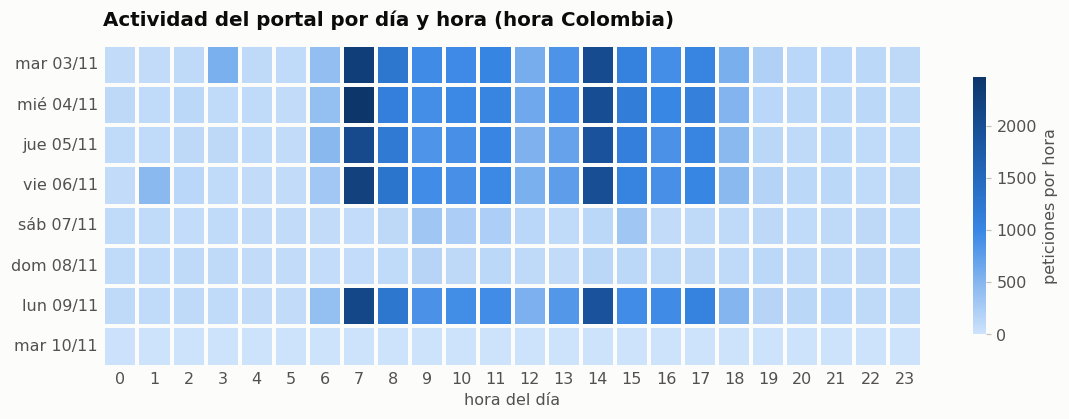

In [6]:
mapa = con.sql('''
    SELECT CAST(ts AS DATE) AS dia, hour(ts) AS hora, COUNT(*) AS n
    FROM web WHERE ts >= ? AND ts < ? GROUP BY ALL ORDER BY 1
''', params=[CASO_INI.to_pydatetime(), CASO_FIN.to_pydatetime()]).df()
mapa['etiqueta'] = mapa['dia'].map(lambda d: f"{DIAS_ES[d.weekday()]} {d:%d/%m}")
tabla = mapa.pivot_table(index='etiqueta', columns='hora', values='n', fill_value=0, sort=False)
tabla = tabla.reindex(columns=range(24), fill_value=0)

fig, ax = plt.subplots(figsize=(12, 3.8))
sns.heatmap(tabla, cmap=RAMPA_AZUL, linewidths=1.5, linecolor=FONDO, ax=ax,
            cbar_kws={'label': 'peticiones por hora', 'shrink': 0.8})
ax.set_title('Actividad del portal por día y hora (hora Colombia)')
ax.set_xlabel('hora del día'); ax.set_ylabel('')
ax.tick_params(length=0)
guardar(fig, 'fig01_mapa_calor_actividad')

**Lectura:** el patrón es el de una oficina: picos de 8:00 a 12:00 y de 14:00 a 18:00 entre semana, poca actividad el fin de semana y un piso nocturno (monitoreo cada minuto y el turno de noche de soporte). La celda de la **madrugada del viernes** se sale de ese patrón y es la primera pista.

## 4. Detección de anomalías

### 4.1 Perfil de comportamiento por IP

Para cada IP se calculan las *features* que separan a un empleado de una herramienta automatizada o de un atacante: volumen, proporción de errores 404 y 5xx, tamaño máximo de respuesta (exfiltración), tamaño máximo de petición (cargas útiles), proporción de POST, de actividad nocturna y de peticiones autenticadas.

In [7]:
perfil = con.sql('''
    SELECT client_ip AS ip,
           COUNT(*)                                        AS peticiones,
           COUNT(DISTINCT uri)                             AS uris_distintas,
           AVG((status = 404)::INT)                        AS tasa_404,
           AVG((status >= 500)::INT)                       AS tasa_5xx,
           SUM(bytes_sent)                                 AS bytes_enviados,
           MAX(bytes_sent)                                 AS max_bytes_respuesta,
           ARG_MAX(ts, bytes_sent)                         AS ts_max_bytes,
           MAX(bytes_received)                             AS max_bytes_peticion,
           AVG((method = 'POST')::INT)                     AS tasa_post,
           AVG((hour(ts) < 6 OR hour(ts) >= 22)::INT)      AS tasa_nocturna,
           AVG((usuario IS NOT NULL)::INT)                 AS tasa_autenticada,
           COUNT(DISTINCT user_agent)                      AS agentes,
           ARG_MAX(user_agent, ts)                         AS ultimo_agente,
           MIN(ts) AS primera, MAX(ts) AS ultima
    FROM web GROUP BY client_ip
''').df()

# Zona de cada IP según el INVENTARIO DE RED de TechCorp (no según si la IP "parece" privada:
# por ejemplo, Python considera privadas las IP de documentación 203.0.113.0/24).
inventario = pd.read_csv(CONTEXTO / 'inventario_red.csv')
redes = sorted(((ipaddress.ip_network(r.red), r.zona) for r in inventario.itertuples()), key=lambda x: -x[0].prefixlen)

def zona(ip):
    a = ipaddress.ip_address(ip)
    if a.is_loopback:
        return 'Local'
    return next((z.replace('LAN oficinas', 'LAN') for red, z in redes if a in red), 'Internet')

perfil['zona'] = perfil['ip'].map(zona)
print(f'{len(perfil):,} IP distintas:', perfil['zona'].value_counts().to_dict())

692 IP distintas: {'LAN': 394, 'VPN': 195, 'Internet': 101, 'Monitoreo': 2}


### 4.2 Puntaje de anomalía: z robusto + Isolation Forest

Se usan dos enfoques complementarios:

* **Puntuación z robusta** (mediana y MAD en vez de media y desviación): dice *en qué* se desvía cada IP y se puede explicar en una diapositiva.
* **Isolation Forest** (aprendizaje no supervisado): detecta combinaciones raras de varias *features* a la vez.

In [8]:
from sklearn.ensemble import IsolationForest

FEATURES = {  # transformación logarítmica para magnitudes con colas largas
    'peticiones': np.log1p, 'uris_distintas': np.log1p, 'tasa_404': None, 'tasa_5xx': None,
    'max_bytes_respuesta': np.log1p, 'max_bytes_peticion': np.log1p, 'tasa_post': None, 'tasa_nocturna': None,
}
X = pd.DataFrame({c: (f(perfil[c]) if f else perfil[c]) for c, f in FEATURES.items()})

def z_robusto(s):
    mediana = s.median()
    escala = 1.4826 * (s - mediana).abs().median()
    if escala == 0:
        escala = s.std() or 1.0
    return (s - mediana) / escala

Z = X.apply(z_robusto)
perfil['z_max'] = Z.abs().max(axis=1).round(1)
perfil['motivo'] = Z.abs().idxmax(axis=1)

iso = IsolationForest(n_estimators=400, contamination='auto', random_state=2026).fit(X)
perfil['puntaje_if'] = (-iso.score_samples(X)).round(3)

cols = ['ip', 'zona', 'peticiones', 'tasa_404', 'tasa_5xx', 'max_bytes_respuesta', 'max_bytes_peticion',
        'tasa_nocturna', 'tasa_autenticada', 'ultimo_agente', 'puntaje_if', 'z_max', 'motivo']
top = perfil.sort_values('puntaje_if', ascending=False).head(15)[cols]
display(top.style.format({'tasa_404': '{:.0%}', 'tasa_5xx': '{:.0%}', 'tasa_nocturna': '{:.0%}', 'tasa_autenticada': '{:.0%}',
                          'max_bytes_respuesta': '{:,}', 'max_bytes_peticion': '{:,}'}).hide(axis='index'))

ip,zona,peticiones,tasa_404,tasa_5xx,max_bytes_respuesta,max_bytes_peticion,tasa_nocturna,tasa_autenticada,ultimo_agente,puntaje_if,z_max,motivo
203.0.113.66,Internet,439,82%,4%,"1,211","874,867",100%,0%,python-requests/2.32.3,0.788000,23.500000,tasa_5xx
10.10.5.20,LAN,463,92%,0%,985,351,100%,0%,TechCorp-SOC-Scanner/3.2 (+https://soc.techcorp.local; CAB-2026-114),0.707000,19.300000,uris_distintas
203.0.113.67,Internet,2,0%,0%,"5,607,810",262,100%,0%,curl/8.5.0,0.704000,26.200000,max_bytes_respuesta
10.10.0.5,Monitoreo,10080,0%,0%,273,217,33%,0%,Zabbix,0.703000,11.900000,uris_distintas
10.10.0.6,Monitoreo,2016,0%,0%,253,254,33%,0%,check_http/v2.3.3 (nagios-plugins 2.3.3),0.689000,11.900000,uris_distintas
192.0.2.233,Internet,1,100%,0%,949,318,100%,0%,"Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/49.0.2623.112 Safari/537.36",0.636000,11.900000,uris_distintas
198.51.100.205,Internet,1,100%,0%,949,221,100%,0%,curl/7.88.1,0.633000,11.900000,uris_distintas
198.51.100.77,Internet,202,90%,0%,"1,010",392,0%,0%,Mozilla/5.0 zgrab/0.x,0.631000,14.200000,uris_distintas
10.8.0.11,VPN,35,3%,0%,"1,891",698,100%,69%,"Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/130.0.0.0 Safari/537.36 Edg/130.0.0.0",0.623000,4.100000,tasa_nocturna
198.51.100.162,Internet,4,25%,0%,985,374,100%,0%,"Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/49.0.2623.112 Safari/537.36",0.619000,6.700000,uris_distintas


### 4.3 Ráfagas de errores 404: reconocimiento

Una herramienta de enumeración (gobuster, dirb, un escáner de vulnerabilidades…) prueba cientos de rutas que no existen en pocos minutos. Se buscan IP con **20 o más 404 en un mismo minuto**.

In [9]:
rafagas = con.sql('''
    WITH m AS (
        SELECT client_ip, date_trunc('minute', ts) AS minuto, COUNT(*) AS n404, ANY_VALUE(user_agent) AS agente
        FROM web WHERE status = 404 GROUP BY ALL
    )
    SELECT client_ip AS ip, MIN(minuto) AS desde, MAX(minuto) + INTERVAL 1 MINUTE AS hasta,
           SUM(n404) AS total_404, MAX(n404) AS max_404_por_minuto, ANY_VALUE(agente) AS user_agent
    FROM m WHERE n404 >= 20 GROUP BY client_ip ORDER BY desde
''').df()
display(rafagas)

,ip,desde,hasta,total_404,max_404_por_minuto,user_agent
0,10.10.5.20,2026-11-03 03:00:00,2026-11-03 03:07:00,426.0,67,TechCorp-SOC-Scanner/3.2 (+https://soc.techcorp.local; CAB-2026-114)
1,203.0.113.66,2026-11-06 01:53:00,2026-11-06 01:55:00,354.0,199,gobuster/3.6
2,198.51.100.77,2026-11-07 15:21:00,2026-11-07 15:24:00,181.0,63,Mozilla/5.0 zgrab/0.x


Aparecen **tres escaneos**. Que haya un escaneo no prueba que hubo una intrusión. Lo que importa es **qué pasó después** con cada IP.

### 4.4 Tamaño de las respuestas: posibles salidas de datos

El volumen de bytes enviados al cliente es el indicador clásico de exfiltración. Se comparan las respuestas más grandes de la semana con la distribución normal.

In [10]:
p99 = con.sql("SELECT quantile_cont(bytes_sent, 0.99) FROM web WHERE status = 200").fetchone()[0]
grandes = con.sql(f'''
    SELECT ts, client_ip, usuario, method, uri, query, status, bytes_sent, user_agent
    FROM web WHERE bytes_sent > 100000 AND uri NOT LIKE '/uploads/avatars/emp_%'
    ORDER BY bytes_sent DESC LIMIT 12
''').df()
print(f'Percentil 99 de una respuesta normal: {num(p99 / 1024, 1)} KB (las páginas viajan comprimidas con gzip)')
display(grandes.style.format({'bytes_sent': '{:,}'}).hide(axis='index'))

Percentil 99 de una respuesta normal: 2,3 KB (las páginas viajan comprimidas con gzip)


ts,client_ip,usuario,method,uri,query,status,bytes_sent,user_agent
2026-11-06 02:23:12.815000,203.0.113.67,None,GET,/uploads/avatars/thumb_8f3a.php,?dl=L3RtcC8udy50Z3o%3D,200,"5,607,810",curl/8.5.0
2026-11-04 10:13:10.008000,10.10.3.112,lmora,GET,/reportes/exportar.php,?tipo=clientes,200,"257,393",Mozilla/5.0 (X11; Ubuntu; Linux x86_64; rv:132.0) Gecko/20100101 Firefox/132.0
2026-11-09 16:42:18.144000,10.10.6.139,lcaicedo,GET,/reportes/exportar.php,?tipo=clientes,200,"257,393",Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:132.0) Gecko/20100101 Firefox/132.0
2026-11-06 02:22:04.309000,203.0.113.67,None,GET,/uploads/avatars/thumb_8f3a.php,?dl=L3RtcC8uZC50Z3o%3D,200,"163,388",curl/8.5.0
2026-11-09 16:43:08.144000,10.10.6.139,lcaicedo,GET,/reportes/exportar.php,?tipo=tickets,200,"110,997",Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:132.0) Gecko/20100101 Firefox/132.0
2026-11-09 16:05:50.643000,10.10.3.228,lflorez2,GET,/reportes/exportar.php,?tipo=tickets,200,"110,188",Mozilla/5.0 (X11; Ubuntu; Linux x86_64; rv:132.0) Gecko/20100101 Firefox/132.0
2026-11-09 15:14:18.898000,10.10.3.131,epardo,GET,/reportes/exportar.php,?tipo=tickets,200,"109,950","Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/129.0.0.0 Safari/537.36"
2026-11-09 17:41:19.491000,10.8.0.171,egomez,GET,/reportes/exportar.php,?tipo=tickets,200,"108,008","Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/130.0.0.0 Safari/537.36"
2026-11-09 18:27:40.248000,10.10.3.166,adiaz,GET,/reportes/exportar.php,?tipo=tickets,200,"105,308","Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/130.0.0.0 Safari/537.36"
2026-11-09 17:17:59.039000,10.10.3.79,lhernandez,GET,/reportes/exportar.php,?tipo=tickets,200,"104,113","Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/605.1.15 (KHTML, like Gecko) Version/18.1 Safari/605.1.15"


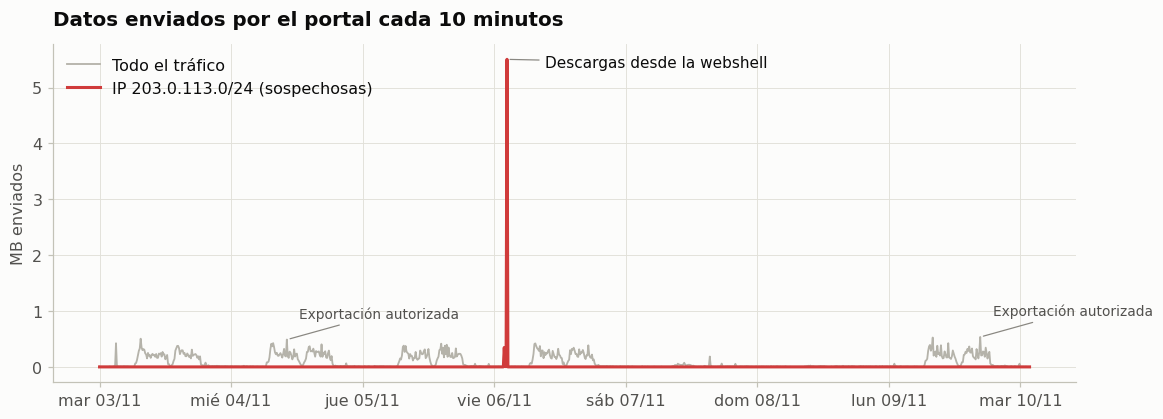

In [11]:
serie = con.sql('''
    SELECT time_bucket(INTERVAL 10 MINUTE, ts) AS t,
           SUM(bytes_sent) / 1048576.0 AS mb_total,
           SUM(CASE WHEN client_ip LIKE '203.0.113.%' THEN bytes_sent ELSE 0 END) / 1048576.0 AS mb_sospechoso
    FROM web WHERE ts >= ? AND ts < ? GROUP BY 1 ORDER BY 1
''', params=[CASO_INI.to_pydatetime(), CASO_FIN.to_pydatetime()]).df()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(serie['t'], serie['mb_total'], color=GRIS, lw=1.2, label='Todo el tráfico')
ax.plot(serie['t'], serie['mb_sospechoso'], color=CRITICO, lw=2, label='IP 203.0.113.0/24 (sospechosas)')
pico_ext = serie.loc[serie['mb_sospechoso'].idxmax()]
ax.annotate('Descargas desde la webshell', xy=(pico_ext['t'], pico_ext['mb_sospechoso']),
            xytext=(25, -5), textcoords='offset points', color=TINTA, fontsize=10,
            arrowprops=dict(arrowstyle='-', color=TENUE, lw=0.8))
exportes = con.sql("SELECT MIN(ts) AS t FROM web WHERE uri = '/reportes/exportar.php' AND query LIKE '%clientes%' AND status = 200 GROUP BY CAST(ts AS DATE)").df()
for t in exportes['t']:
    y = serie.loc[(serie['t'] - t).abs().idxmin(), 'mb_total']
    ax.annotate('Exportación autorizada', xy=(t, y), xytext=(8, 14), textcoords='offset points', color=TINTA2, fontsize=9,
                arrowprops=dict(arrowstyle='-', color=TENUE, lw=0.8))
ax.set_title('Datos enviados por el portal cada 10 minutos')
ax.set_ylabel('MB enviados')
ax.xaxis.set_major_locator(mdates.DayLocator())
formato_dias(ax)
ax.legend(loc='upper left')
guardar(fig, 'fig02_bytes_enviados')

### 4.5 Triage con contexto: descartar las falsas alarmas

Una anomalía estadística no es un incidente. Se cruza cada IP sospechosa con el **registro de cambios aprobados** (CAB) y el **inventario de red** que entregó TechCorp.

In [12]:
cambios = pd.read_csv(CONTEXTO / 'registro_cambios.csv', parse_dates=['fecha_inicio_local', 'fecha_fin_local'])
display(cambios)

def explicar(fila):
    ip = ipaddress.ip_address(fila.ip)
    for c in cambios.itertuples():
        red = ipaddress.ip_network(c.ip_origen, strict=False)
        ini, fin = c.fecha_inicio_local.tz_localize(None), c.fecha_fin_local.tz_localize(None)
        # La anomalía (su respuesta más grande / su actividad) debe caer dentro de la ventana aprobada
        if ip in red and ini <= fila.ts_max_bytes <= fin:
            return f'Autorizado ({c.id_cambio})'
    if fila.zona == 'Monitoreo':
        return 'Monitoreo (inventario de red)'
    if fila.zona == 'Local':
        return 'Conexión interna del propio servidor'
    if fila.zona in ('LAN', 'VPN') and fila.tasa_autenticada > 0.5:
        return 'Empleado autenticado'
    return None

# IP llamativas: top del Isolation Forest + las de ráfagas 404 + las de respuestas grandes
llamativas = set(top['ip']) | set(rafagas['ip']) | set(grandes['client_ip'])
triage = perfil[perfil['ip'].isin(llamativas)].copy()
triage['explicacion'] = triage.apply(explicar, axis=1)

# ¿La IP obtuvo algo más que el formulario de login? (éxito tras el escaneo)
exito = con.sql('''
    SELECT client_ip AS ip, COUNT(*) AS respuestas_200_no_publicas, ANY_VALUE(uri) AS ejemplo
    FROM web
    WHERE status = 200 AND usuario IS NULL
      AND uri NOT IN ('/login.php', '/robots.txt', '/favicon.ico', '/api/health.php', '/legacy/status.php')
      AND uri NOT LIKE '/assets/%'
    GROUP BY 1
''').df()
triage = triage.merge(exito, on='ip', how='left').fillna({'respuestas_200_no_publicas': 0})
triage['veredicto'] = np.where(triage['explicacion'].notna(), 'Explicada (falsa alarma)',
                       np.where(triage['respuestas_200_no_publicas'] > 0, 'SOSPECHOSA: obtuvo respuestas fuera del login',
                                'Escaneo/ruido externo sin éxito'))
display(triage.sort_values(['veredicto', 'puntaje_if'], ascending=[False, False])[
    ['ip', 'zona', 'peticiones', 'tasa_404', 'max_bytes_respuesta', 'ultimo_agente', 'explicacion',
     'respuestas_200_no_publicas', 'ejemplo', 'veredicto']].style.format({'tasa_404': '{:.0%}', 'max_bytes_respuesta': '{:,}'}).hide(axis='index'))

SOSPECHOSAS = sorted(triage.loc[triage['veredicto'].str.startswith('SOSPECHOSA'), 'ip'])
print('IP que requieren investigación:', SOSPECHOSAS)

,id_cambio,fecha_inicio_local,fecha_fin_local,ip_origen,descripcion,aprobado_por
0,CAB-2026-114,2026-11-03 02:30:00-05:00,2026-11-03 04:30:00-05:00,10.10.5.20,Escaneo trimestral de vulnerabilidades del portal interno (SOC),Comité de cambios TI
1,CAB-2026-117,2026-11-04 09:00:00-05:00,2026-11-04 12:00:00-05:00,10.10.3.0/24,Cierre de cartera: exportación de base de clientes para conciliación (Finanzas),Dirección financiera
2,CAB-2026-121,2026-11-09 16:00:00-05:00,2026-11-09 18:00:00-05:00,10.10.6.0/24,Informe mensual de gerencia: exportación de clientes,Gerencia general


ip,zona,peticiones,tasa_404,max_bytes_respuesta,ultimo_agente,explicacion,respuestas_200_no_publicas,ejemplo,veredicto
203.0.113.66,Internet,439,82%,"1,211",python-requests/2.32.3,None,24.000000,/uploads/avatars/thumb_8f3a.php,SOSPECHOSA: obtuvo respuestas fuera del login
203.0.113.67,Internet,2,0%,"5,607,810",curl/8.5.0,None,2.000000,/uploads/avatars/thumb_8f3a.php,SOSPECHOSA: obtuvo respuestas fuera del login
10.10.5.20,LAN,463,92%,985,TechCorp-SOC-Scanner/3.2 (+https://soc.techcorp.local; CAB-2026-114),Autorizado (CAB-2026-114),0.000000,nan,Explicada (falsa alarma)
10.10.0.5,Monitoreo,10080,0%,273,Zabbix,Monitoreo (inventario de red),0.000000,nan,Explicada (falsa alarma)
10.10.0.6,Monitoreo,2016,0%,253,check_http/v2.3.3 (nagios-plugins 2.3.3),Monitoreo (inventario de red),0.000000,nan,Explicada (falsa alarma)
10.8.0.11,VPN,35,3%,"1,891","Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/130.0.0.0 Safari/537.36 Edg/130.0.0.0",Empleado autenticado,0.000000,nan,Explicada (falsa alarma)
10.10.3.229,LAN,174,1%,"103,737","Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/605.1.15 (KHTML, like Gecko) Version/18.1 Safari/605.1.15",Empleado autenticado,2.000000,/uploads/avatars/emp_390.png,Explicada (falsa alarma)
10.10.3.112,LAN,125,0%,"257,393",Mozilla/5.0 (X11; Ubuntu; Linux x86_64; rv:132.0) Gecko/20100101 Firefox/132.0,Autorizado (CAB-2026-117),1.000000,/uploads/avatars/emp_11.png,Explicada (falsa alarma)
10.10.6.139,LAN,117,1%,"257,393",Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:132.0) Gecko/20100101 Firefox/132.0,Autorizado (CAB-2026-121),0.000000,nan,Explicada (falsa alarma)
10.8.0.171,VPN,86,1%,"108,008","Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/130.0.0.0 Safari/537.36",Empleado autenticado,0.000000,nan,Explicada (falsa alarma)


IP que requieren investigación: ['203.0.113.66', '203.0.113.67']


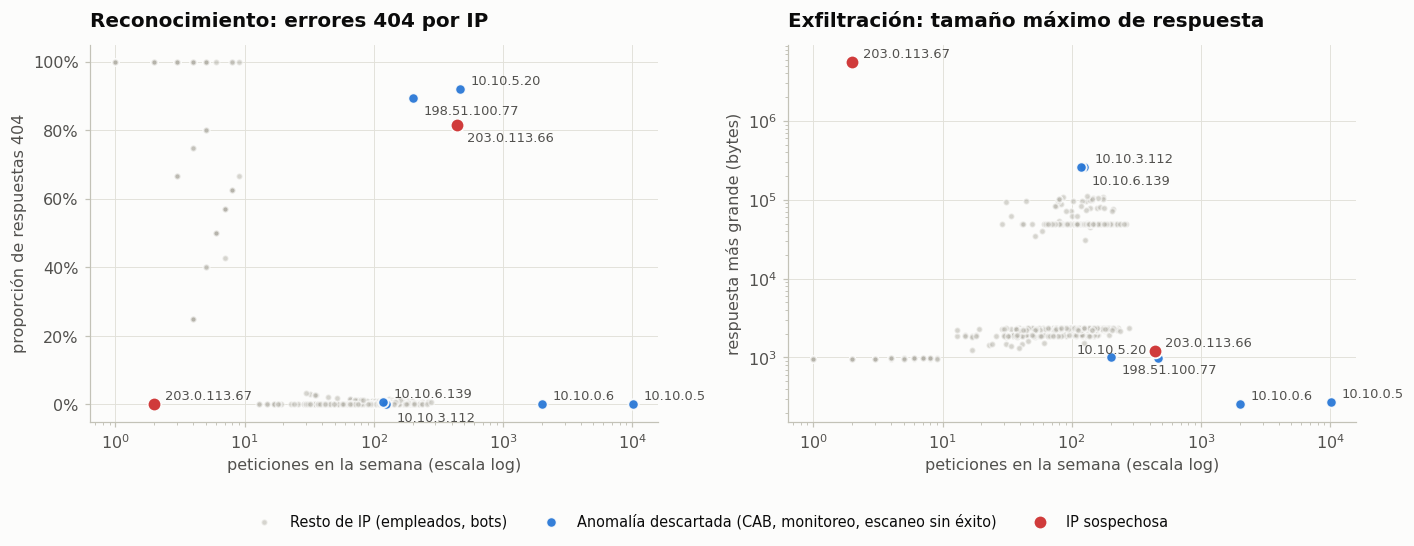

In [13]:
# Figura para la presentación: dónde cae cada IP en dos dimensiones clave
cat = perfil[['ip', 'zona', 'peticiones', 'tasa_404', 'max_bytes_respuesta']].copy()
# Anomalías descartadas que se discuten en la presentación: escaneos, monitoreo y las 2 exportaciones más grandes
exportadores = set(perfil[(perfil['zona'] == 'LAN') & ~perfil['ip'].isin(SOSPECHOSAS)].nlargest(2, 'max_bytes_respuesta')['ip'])
descartadas = (set(rafagas['ip']) | set(perfil.loc[perfil['zona'] == 'Monitoreo', 'ip']) | exportadores) - set(SOSPECHOSAS)
cat['grupo'] = np.where(cat['ip'].isin(SOSPECHOSAS), 'sospechosa', np.where(cat['ip'].isin(descartadas), 'descartada', 'otra'))
estilos = {'otra': (GRIS, 'Resto de IP (empleados, bots)', 16, 0.55),
           'descartada': (AZUL, 'Anomalía descartada (CAB, monitoreo, escaneo sin éxito)', 46, 0.95),
           'sospechosa': (CRITICO, 'IP sospechosa', 80, 1.0)}

def rotulos_sin_solape(ax, puntos):
    # Prueba varias posiciones alrededor de cada punto y usa la primera cuya caja no choca con otra
    r = ax.figure.canvas.get_renderer()
    cajas = []
    candidatos = [(7, 3, 'left'), (7, -11, 'left'), (-7, 3, 'right'), (-7, -11, 'right'), (7, 16, 'left'), (7, -24, 'left'), (-7, 16, 'right')]
    for x, yv, texto in sorted(puntos, key=lambda p: -ax.transData.transform((p[0], p[1]))[1]):
        for dx, dy, ha in candidatos:
            a = ax.annotate(texto, (x, yv), xytext=(dx, dy), textcoords='offset points', fontsize=8.5, color=TINTA2, ha=ha)
            caja = a.get_window_extent(r)
            if not any(caja.overlaps(c) for c in cajas):
                break
            a.remove()
        else:  # ninguna posición libre: se deja en la primera
            a = ax.annotate(texto, (x, yv), xytext=(7, 3), textcoords='offset points', fontsize=8.5, color=TINTA2)
            caja = a.get_window_extent(r)
        cajas.append(caja)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (ycol, ytit) in zip(axs, [('tasa_404', 'proporción de respuestas 404'), ('max_bytes_respuesta', 'respuesta más grande (bytes)')]):
    for g in ['otra', 'descartada', 'sospechosa']:
        d = cat[cat['grupo'] == g]
        color, etiqueta, tam, alfa = estilos[g]
        ax.scatter(d['peticiones'], d[ycol], s=tam, color=color, alpha=alfa, edgecolor=FONDO, linewidth=1.2, label=etiqueta, zorder=3)
    ax.set_xscale('log'); ax.set_xlabel('peticiones en la semana (escala log)'); ax.set_ylabel(ytit)
    if ycol == 'max_bytes_respuesta':
        ax.set_yscale('log')
    else:
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
    fig.canvas.draw()
    rotulos_sin_solape(ax, [(f.peticiones, getattr(f, ycol), f.ip) for f in cat[cat['grupo'] != 'otra'].itertuples()])
axs[0].set_title('Reconocimiento: errores 404 por IP')
axs[1].set_title('Exfiltración: tamaño máximo de respuesta')
fig.legend(*axs[0].get_legend_handles_labels(), loc='lower center', ncol=3, fontsize=9.5, bbox_to_anchor=(0.5, -0.04))
fig.tight_layout(rect=(0, 0.06, 1, 1))
guardar(fig, 'fig03_ips_anomalas')

## 5. Vector de entrada: ¿cómo entró el atacante?

### 5.1 Peticiones POST anómalas contra `/login.php`

Un inicio de sesión normal es un formulario `application/x-www-form-urlencoded` de unos 60 bytes. Se buscan POST a `/login.php` con cuerpos grandes o de tipo `multipart/form-data`.

In [14]:
display(con.sql('''
    SELECT CASE WHEN content_type LIKE 'multipart/%' THEN 'multipart/form-data' ELSE content_type END AS tipo,
           COUNT(*) AS peticiones, COUNT(DISTINCT client_ip) AS ips,
           quantile_cont(bytes_received, 0.5)::INT AS mediana_bytes_peticion, MAX(bytes_received) AS max_bytes_peticion,
           SUM((status = 500)::INT) AS respuestas_500
    FROM web WHERE uri = '/login.php' AND method = 'POST' GROUP BY 1
''').df())

posts = con.sql('''
    SELECT ts, client_ip, status, bytes_received, bytes_sent, user_agent, request_id
    FROM web WHERE uri = '/login.php' AND method = 'POST' AND content_type LIKE 'multipart/%'
    ORDER BY ts
''').df()
display(posts)

,tipo,peticiones,ips,mediana_bytes_peticion,max_bytes_peticion,respuestas_500
0,application/x-www-form-urlencoded,3552,589,532,550,0.0
1,multipart/form-data,19,1,555746,874867,18.0


,ts,client_ip,status,bytes_received,bytes_sent,user_agent,request_id
0,2026-11-06 02:03:28.986,203.0.113.66,500,387027,211,python-requests/2.32.3,avtHHErIKu1KPmYJyqwPHQAAAAI
1,2026-11-06 02:03:42.324,203.0.113.66,500,694167,211,python-requests/2.32.3,avtHHJtgw7MB-T5k0a0tYAAAAAM
2,2026-11-06 02:03:55.047,203.0.113.66,500,811680,211,python-requests/2.32.3,avtHHFPsqgpZ3IMJCztlJAAAABU
3,2026-11-06 02:04:09.971,203.0.113.66,500,651937,211,python-requests/2.32.3,avtHHExB8BnCiEG0nj7xJAAAABM
4,2026-11-06 02:04:22.351,203.0.113.66,500,506486,211,python-requests/2.32.3,avtHHPssYfJibS2S1pa6BQAAABY
5,2026-11-06 02:04:33.541,203.0.113.66,500,874867,211,python-requests/2.32.3,avtHHMnV_JT99EM2_WH7qQAAAA0
6,2026-11-06 02:04:47.633,203.0.113.66,500,369415,211,python-requests/2.32.3,avtHHRN4LfikNjE-UucsXgAAABc
7,2026-11-06 02:05:02.601,203.0.113.66,500,391864,211,python-requests/2.32.3,avtHHVKAy7kaud4_Dzb2xAAAABI
8,2026-11-06 02:05:14.945,203.0.113.66,500,395554,211,python-requests/2.32.3,avtHHVKAy7kaud4_Dzb2xgAAABI
9,2026-11-06 02:05:32.793,203.0.113.66,500,376205,211,python-requests/2.32.3,avtHHUxB8BnCiEG0nj7xJQAAABM


### 5.2 Correlación por tiempo con las caídas de Apache

El registro de Apache anota cada proceso que muere con `Segmentation fault` (**AH00052**), pero **no dice qué petición lo provocó**. Se correlaciona por tiempo con un `ASOF JOIN`: para cada caída se busca la última petición recibida antes de ella.

In [15]:
caidas = con.sql('''
    WITH c AS (SELECT ts, message FROM app WHERE event = 'child_crash'),
         w AS (SELECT ts AS ts_peticion, client_ip, method, uri, status, bytes_received FROM web)
    SELECT c.ts AS ts_caida, c.message, w.ts_peticion,
           ROUND(epoch(c.ts - w.ts_peticion) * 1000)::INT AS ms_despues,
           w.client_ip, w.method, w.uri, w.status, w.bytes_received
    FROM c ASOF JOIN w ON c.ts >= w.ts_peticion
    ORDER BY c.ts
''').df()
display(caidas)
print(f"{len(caidas)} caídas; todas siguen a un POST multipart de "
      f"{', '.join(caidas['client_ip'].unique())} con {caidas['ms_despues'].max()} ms de diferencia como máximo.")

,ts_caida,message,ts_peticion,ms_despues,client_ip,method,uri,status,bytes_received
0,2026-11-06 02:03:28.986,AH00052: child pid 9678 exit signal Segmentation fault (11),2026-11-06 02:03:28.986,0,203.0.113.66,POST,/login.php,500,387027
1,2026-11-06 02:03:42.324,AH00052: child pid 8181 exit signal Segmentation fault (11),2026-11-06 02:03:42.324,0,203.0.113.66,POST,/login.php,500,694167
2,2026-11-06 02:03:55.051,AH00052: child pid 9695 exit signal Segmentation fault (11),2026-11-06 02:03:55.047,4,203.0.113.66,POST,/login.php,500,811680
3,2026-11-06 02:04:09.971,AH00052: child pid 2207 exit signal Segmentation fault (11),2026-11-06 02:04:09.971,0,203.0.113.66,POST,/login.php,500,651937
4,2026-11-06 02:04:22.351,AH00052: child pid 8193 exit signal Segmentation fault (11),2026-11-06 02:04:22.351,0,203.0.113.66,POST,/login.php,500,506486
5,2026-11-06 02:04:33.550,AH00052: child pid 4280 exit signal Segmentation fault (11),2026-11-06 02:04:33.541,9,203.0.113.66,POST,/login.php,500,874867
6,2026-11-06 02:04:47.699,AH00052: child pid 4756 exit signal Segmentation fault (11),2026-11-06 02:04:47.633,66,203.0.113.66,POST,/login.php,500,369415
7,2026-11-06 02:05:02.601,AH00052: child pid 8286 exit signal Segmentation fault (11),2026-11-06 02:05:02.601,0,203.0.113.66,POST,/login.php,500,391864
8,2026-11-06 02:05:14.948,AH00052: child pid 1965 exit signal Segmentation fault (11),2026-11-06 02:05:14.945,3,203.0.113.66,POST,/login.php,500,395554
9,2026-11-06 02:05:32.793,AH00052: child pid 8811 exit signal Segmentation fault (11),2026-11-06 02:05:32.793,0,203.0.113.66,POST,/login.php,500,376205


18 caídas; todas siguen a un POST multipart de 203.0.113.66 con 66 ms de diferencia como máximo.


### 5.3 Aparición de un archivo PHP nuevo (FIM) y primer acceso a él

In [16]:
fim_php = con.sql("SELECT ts, event, path, size, sha256, owner, mode FROM fim WHERE path LIKE '%.php' ORDER BY ts").df()
display(fim_php)
print('Eventos FIM de archivos de imagen (fotos de perfil legítimas):',
      con.sql("SELECT COUNT(*) FROM fim WHERE path NOT LIKE '%.php'").fetchone()[0])

WEBSHELL = fim_php.iloc[0]['path'].replace('/var/www/html', '')
T_IMPLANTE = fim_php.iloc[0]['ts']

ultimo_post = posts[posts['ts'] <= T_IMPLANTE].iloc[-1]
primer_200 = con.sql('SELECT MIN(ts) FROM web WHERE uri = ? AND status = 200', params=[WEBSHELL]).fetchone()[0]
previos_404 = con.sql('SELECT COUNT(*) FROM web WHERE uri = ? AND status = 404', params=[WEBSHELL]).fetchone()[0]

uris_nuevas = con.sql('''
    SELECT uri, MIN(ts) AS primera_vez, COUNT(*) AS peticiones, COUNT(DISTINCT client_ip) AS ips,
           list(DISTINCT client_ip) AS lista_ips
    FROM web WHERE status = 200 AND uri LIKE '%.php'
    GROUP BY uri
    HAVING MIN(ts) > (SELECT MIN(ts) FROM web) + INTERVAL 1 DAY   -- URI que "nace" a mitad de la semana
    ORDER BY primera_vez
''').df()
display(uris_nuevas)

display(Markdown(f'''
* **Último POST explotador** (no devolvió 500): `{ultimo_post.ts}` desde **{ultimo_post.client_ip}** (`{ultimo_post.user_agent}`), {num(ultimo_post.bytes_received)} bytes de cuerpo.
* **Creación de la webshell (FIM):** `{T_IMPLANTE}` → `{fim_php.iloc[0]['path']}` (propietario `{fim_php.iloc[0]['owner']}`, SHA-256 `{fim_php.iloc[0]['sha256'][:16]}…`), **{(T_IMPLANTE - ultimo_post.ts).total_seconds() * 1000:.0f} ms** después del POST.
* Antes de eso, el atacante consultó **{previos_404} veces** `{WEBSHELL}` y recibió 404: estaba esperando a que el exploit funcionara. **Primer 200:** `{primer_200}`.
* Es la única URI `.php` que empezó a responder 200 a mitad de la semana (no existía antes): es el artefacto del ataque.
'''))

,ts,event,path,size,sha256,owner,mode
0,2026-11-06 02:07:46.545,file_added,/var/www/html/uploads/avatars/thumb_8f3a.php,207,a0a401e8e0260ef38cb542a3c867cb717d66b364bdecb99cc81182522e153c1e,www-data,0644


Eventos FIM de archivos de imagen (fotos de perfil legítimas): 192


,uri,primera_vez,peticiones,ips,lista_ips
0,/uploads/avatars/thumb_8f3a.php,2026-11-06 02:07:48.685,26,2,"[203.0.113.66, 203.0.113.67]"



* **Último POST explotador** (no devolvió 500): `2026-11-06 02:07:46.545000` desde **203.0.113.66** (`python-requests/2.32.3`), 708.896 bytes de cuerpo.
* **Creación de la webshell (FIM):** `2026-11-06 02:07:46.545000` → `/var/www/html/uploads/avatars/thumb_8f3a.php` (propietario `www-data`, SHA-256 `a0a401e8e0260ef3…`), **0 ms** después del POST.
* Antes de eso, el atacante consultó **4 veces** `/uploads/avatars/thumb_8f3a.php` y recibió 404: estaba esperando a que el exploit funcionara. **Primer 200:** `2026-11-06 02:07:48.685000`.
* Es la única URI `.php` que empezó a responder 200 a mitad de la semana (no existía antes): es el artefacto del ataque.


## 6. Post-explotación: ¿qué órdenes ejecutó?

La webshell recibe las órdenes en Base64 dentro del parámetro `x` (y las descargas en `dl`), un truco habitual para esquivar filtros simples. Como Apache registra la *query string*, **las órdenes se pueden decodificar**. Además, cada una se asocia a su técnica de **MITRE ATT&CK**.

In [17]:
ws = con.sql('''
    SELECT ts, client_ip, user_agent, query, status, bytes_sent, request_id
    FROM web WHERE uri = ? AND status = 200 ORDER BY ts
''', params=[WEBSHELL]).df()

def decodificar(query):
    q = parse_qs((query or '').lstrip('?'))
    for clave, tipo in (('x', 'orden'), ('dl', 'descarga')):
        if clave in q:
            try:
                return tipo, base64.b64decode(q[clave][0]).decode('utf-8', 'replace')
            except Exception:
                return tipo, '<no decodificable>'
    return 'acceso', ''

ws[['tipo', 'orden']] = ws['query'].apply(lambda q: pd.Series(decodificar(q)))
ws['orden_segura'] = ws['orden'].str.replace(r"-p'[^']*'", "-p'********'", regex=True)  # no mostrar contraseñas

MITRE = [
    (r'^(id|whoami|hostname|uname|pwd|php -v)', 'T1082 Descubrimiento de información del sistema'),
    (r'^ls ', 'T1083 Descubrimiento de archivos y directorios'),
    (r'^cat .*config', 'T1552.001 Credenciales en archivos'),
    (r'^mysql .*(SHOW TABLES|COUNT)', 'T1078 Cuentas válidas (BD) + reconocimiento de tablas'),
    (r'^mysql .*SELECT \*', 'T1005 Datos del sistema local (volcado de tablas)'),
    (r'^mkdir', 'T1074.001 Preparación de datos en local'),
    (r'^(tar|du)', 'T1560.001 Compresión de datos para exfiltrar'),
    (r'^/tmp/', 'T1041 Exfiltración por el canal de C2 (descarga HTTP)'),
    (r'^rm ', 'T1070.004 Borrado de archivos (antiforense)'),
]
ws['mitre'] = ws['orden'].apply(lambda o: next((t for p, t in MITRE if re.search(p, o)), 'T1505.003 Webshell (acceso)'))
pd.set_option('display.max_colwidth', 95)
display(ws[['ts', 'client_ip', 'user_agent', 'tipo', 'orden_segura', 'bytes_sent', 'mitre']].style
        .format({'bytes_sent': '{:,}'}).hide(axis='index'))

ts,client_ip,user_agent,tipo,orden_segura,bytes_sent,mitre
2026-11-06 02:07:48.685000,203.0.113.66,python-requests/2.32.3,acceso,,229,T1505.003 Webshell (acceso)
2026-11-06 02:08:10.606000,203.0.113.66,python-requests/2.32.3,orden,id,284,T1082 Descubrimiento de información del sistema
2026-11-06 02:08:49.224000,203.0.113.66,python-requests/2.32.3,orden,whoami,238,T1082 Descubrimiento de información del sistema
2026-11-06 02:09:15.731000,203.0.113.66,python-requests/2.32.3,orden,uname -a,390,T1082 Descubrimiento de información del sistema
2026-11-06 02:09:59.095000,203.0.113.66,python-requests/2.32.3,orden,pwd,260,T1082 Descubrimiento de información del sistema
2026-11-06 02:10:32.534000,203.0.113.66,python-requests/2.32.3,orden,php -v,399,T1082 Descubrimiento de información del sistema
2026-11-06 02:11:08.186000,203.0.113.66,python-requests/2.32.3,orden,ls -la /var/www/html,578,T1083 Descubrimiento de archivos y directorios
2026-11-06 02:11:32.213000,203.0.113.66,python-requests/2.32.3,orden,ls -la /var/www/html/config,396,T1083 Descubrimiento de archivos y directorios
2026-11-06 02:11:50.047000,203.0.113.66,python-requests/2.32.3,orden,cat /var/www/html/config/database.php,554,T1552.001 Credenciales en archivos
2026-11-06 02:13:31.480000,203.0.113.66,python-requests/2.32.3,orden,"mysql -h db -u techcorp_admin -p'********' techcorp -e ""SHOW TABLES""",276,T1078 Cuentas válidas (BD) + reconocimiento de tablas


## 7. Correlación web ↔ base de datos: ¿qué registros se consultaron?

Cada sentencia SQL lleva un comentario con el `request_id` de la petición HTTP que la originó (`/*request_id='…',route='…'*/`, práctica *sqlcommenter*). Con una expresión regular se recupera ese identificador y se **unen las dos fuentes**.

In [18]:
PATRON_ID = "request_id=''([^'']+)''"     # comillas dobladas = comilla literal en SQL
PATRON_RUTA = "route=''([^'']+)''"
con.execute(f'''
    CREATE OR REPLACE TABLE db_c AS
    SELECT *, regexp_extract(sqltext, '{PATRON_ID}', 1)   AS request_id,
              regexp_extract(sqltext, '{PATRON_RUTA}', 1) AS ruta
    FROM db
''')
display(con.sql('''
    SELECT db_user, COUNT(*) AS sentencias, COUNT(DISTINCT ruta) AS rutas, MIN(ts) AS primera, MAX(ts) AS ultima,
           SUM(rows_sent) AS filas_leidas, list(DISTINCT ruta)[:4] AS ejemplos_de_ruta
    FROM db_c GROUP BY 1 ORDER BY 2 DESC
''').df())

,db_user,sentencias,rutas,primera,ultima,filas_leidas,ejemplos_de_ruta
0,techcorp_app,88508,15,2026-11-03 00:00:01.319,2026-11-10 01:42:40.107,387060.0,"[/api/health.php, /dashboard.php, /tickets/nuevo.php, /clientes/ver.php]"
1,techcorp_admin,8,1,2026-11-06 02:13:31.527,2026-11-06 02:18:44.332,2505.0,[/uploads/avatars/thumb_8f3a.php]


**Escalada de privilegios:** durante toda la semana el portal usó solo la cuenta de mínimo privilegio `techcorp_app`. La cuenta de mantenimiento **`techcorp_admin`** aparece **únicamente** en la madrugada del incidente y **solo** desde la ruta de la webshell, justo después de que el atacante leyera `config/database.php`.

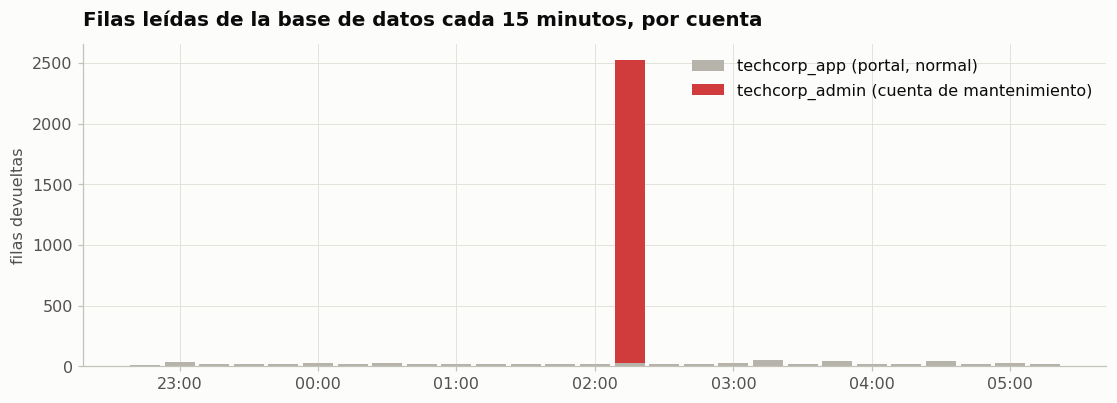

In [19]:
filas_hora = con.sql('''
    SELECT time_bucket(INTERVAL 15 MINUTE, ts) AS t, db_user, SUM(rows_sent) AS filas
    FROM db_c WHERE ts BETWEEN (SELECT MIN(ts) FROM web WHERE client_ip LIKE '203.0.113.%') - INTERVAL 3 HOUR
                           AND (SELECT MAX(ts) FROM web WHERE client_ip LIKE '203.0.113.%') + INTERVAL 3 HOUR
    GROUP BY ALL ORDER BY 1
''').df().pivot_table(index='t', columns='db_user', values='filas', fill_value=0)

fig, ax = plt.subplots(figsize=(12, 3.8))
ancho = 13 / (24 * 60)          # 13 minutos, en días (unidad de matplotlib)
ax.bar(filas_hora.index, filas_hora.get('techcorp_app', 0), width=ancho, color=GRIS, label='techcorp_app (portal, normal)')
ax.bar(filas_hora.index, filas_hora.get('techcorp_admin', 0), width=ancho, color=CRITICO,
       bottom=filas_hora.get('techcorp_app', 0), label='techcorp_admin (cuenta de mantenimiento)')
ax.set_title('Filas leídas de la base de datos cada 15 minutos, por cuenta')
ax.set_ylabel('filas devueltas')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax.legend(loc='upper right')
guardar(fig, 'fig04_bd_filas_por_cuenta')

In [20]:
ids_ataque = list(ws['request_id'])
consultas = con.sql(r'''
    SELECT d.ts, w.client_ip, d.db_user, d.command_class, d.tables, d.rows_sent,
           regexp_replace(d.sqltext, '\s*/\*.*\*/', '') AS sql, d.request_id
    FROM db_c d JOIN web w USING (request_id)
    WHERE d.request_id IN (SELECT UNNEST(?::VARCHAR[]))
    ORDER BY d.ts
''', params=[ids_ataque]).df()
display(consultas)

expuestos = con.sql('''
    SELECT tables[1] AS tabla, UNNEST(row_ids) AS id
    FROM db_c WHERE request_id IN (SELECT UNNEST(?::VARCHAR[])) AND command_class = 'select' AND len(row_ids) > 0
''', params=[ids_ataque]).df().drop_duplicates()
resumen_exp = expuestos.groupby('tabla')['id'].agg(registros='nunique', id_min='min', id_max='max').reset_index()
display(resumen_exp)

,ts,client_ip,db_user,command_class,tables,rows_sent,sql,request_id
0,2026-11-06 02:13:31.527,203.0.113.66,techcorp_admin,show,[],3,SHOW TABLES,avtHH0rIKu1KPmYJyqwPKQAAAAI
1,2026-11-06 02:14:04.626,203.0.113.66,techcorp_admin,select,[clientes],1,SELECT COUNT(*) AS total FROM clientes,avtHH0rIKu1KPmYJyqwPKgAAAAI
2,2026-11-06 02:14:28.434,203.0.113.66,techcorp_admin,select,[empleados],1,SELECT COUNT(*) AS total FROM empleados,avtHH0rIKu1KPmYJyqwPKwAAAAI
3,2026-11-06 02:16:00.935,203.0.113.66,techcorp_admin,select,[clientes],500,SELECT * FROM clientes ORDER BY id LIMIT 500 OFFSET 0,avtHH0rIKu1KPmYJyqwPLQAAAAI
4,2026-11-06 02:16:37.110,203.0.113.66,techcorp_admin,select,[clientes],500,SELECT * FROM clientes ORDER BY id LIMIT 500 OFFSET 500,avtHH0rIKu1KPmYJyqwPLgAAAAI
5,2026-11-06 02:17:07.952,203.0.113.66,techcorp_admin,select,[clientes],500,SELECT * FROM clientes ORDER BY id LIMIT 500 OFFSET 1000,avtHH0rIKu1KPmYJyqwPLwAAAAI
6,2026-11-06 02:17:58.381,203.0.113.66,techcorp_admin,select,[clientes],500,SELECT * FROM clientes ORDER BY id LIMIT 500 OFFSET 1500,avtHH0rIKu1KPmYJyqwPMAAAAAI
7,2026-11-06 02:18:44.332,203.0.113.66,techcorp_admin,select,[empleados],500,SELECT * FROM empleados ORDER BY id,avtHH0rIKu1KPmYJyqwPMQAAAAI


,tabla,registros,id_min,id_max
0,clientes,2000,1,2000
1,empleados,500,1,500


### 7.1 Validación independiente: reproducir las consultas sobre la base de datos

`row_ids` es una extensión de este laboratorio. En un caso real, lo usual es **reproducir** las consultas registradas sobre una copia de la base de datos (con una cuenta de **solo lectura**) para saber qué filas devolvieron. Si las dos vías coinciden, la conclusión es sólida.

In [21]:
import pymysql

def conectar_ro():
    return pymysql.connect(host=os.environ.get('DB_HOST', 'db'), user=os.environ.get('DB_FORENSE_USER', 'forense_ro'),
                           password=os.environ.get('DB_FORENSE_PASSWORD', ''), database=os.environ.get('DB_NAME', 'techcorp'),
                           charset='utf8mb4', cursorclass=pymysql.cursors.DictCursor, connect_timeout=5)

replay = {}
try:
    cn = conectar_ro()
    with cn.cursor() as cur:
        for sql in consultas.loc[consultas['sql'].str.match(r'^SELECT \* FROM'), 'sql']:
            assert sql.upper().startswith('SELECT')
            tabla = re.search(r'FROM (\w+)', sql).group(1)
            cur.execute(sql.replace('SELECT *', 'SELECT id', 1))
            replay.setdefault(tabla, set()).update(r['id'] for r in cur.fetchall())
    BD_DISPONIBLE = True
except Exception as e:
    BD_DISPONIBLE = False
    print('No se pudo conectar a la BD para la reproducción (se usa solo la auditoría):', e)

if BD_DISPONIBLE:
    for tabla, ids in replay.items():
        audit = set(expuestos.loc[expuestos['tabla'] == tabla, 'id'])
        print(f'{tabla:10s}: reproducción = {num(len(ids))} filas · auditoría = {num(len(audit))} · coinciden: {ids == audit}')

clientes  : reproducción = 2.000 filas · auditoría = 2.000 · coinciden: True
empleados : reproducción = 500 filas · auditoría = 500 · coinciden: True


,datos sensibles expuestos
tabla,
clientes,"Contacto, Dato personal, Documento de identidad, Financiero"
empleados,"Contacto, Credencial (hash bcrypt), Documento de identidad, Financiero (salario)"


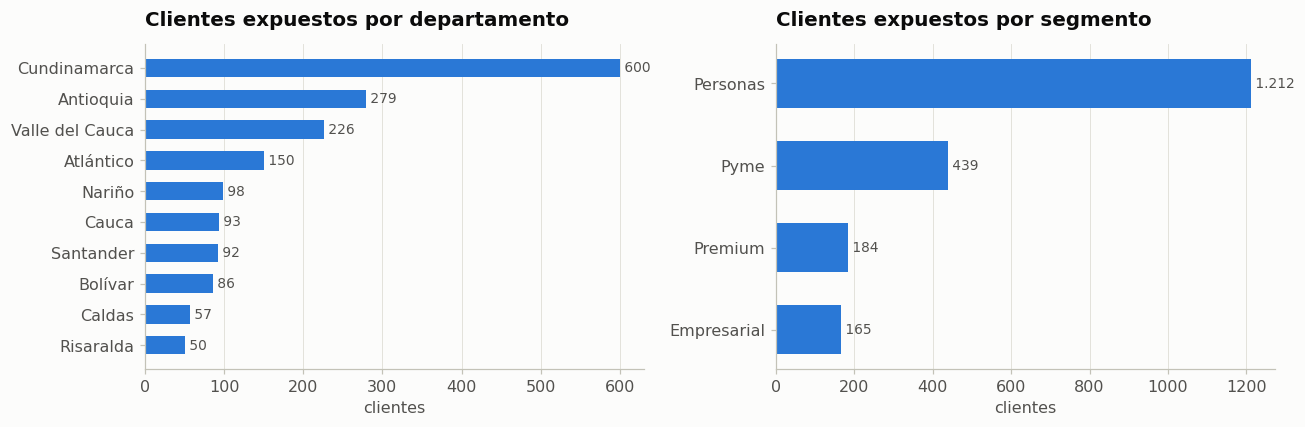

Listados para notificación (Ley 1581 de 2012): salida/registros_expuestos_clientes.csv y registros_expuestos_empleados.csv


In [22]:
if BD_DISPONIBLE:
    ids_cli = sorted(int(i) for i in expuestos.loc[expuestos['tabla'] == 'clientes', 'id'])
    ids_emp = sorted(int(i) for i in expuestos.loc[expuestos['tabla'] == 'empleados', 'id'])
    with cn.cursor() as cur:
        cur.execute(f"SELECT id, tipo_documento, nombres, apellidos, correo, telefono, ciudad, departamento, segmento "
                    f"FROM clientes WHERE id IN ({','.join(map(str, ids_cli)) or 'NULL'})")
        clientes_exp = pd.DataFrame(cur.fetchall())
        cur.execute(f"SELECT id, usuario, nombres, apellidos, correo, departamento, rol "
                    f"FROM empleados WHERE id IN ({','.join(map(str, ids_emp)) or 'NULL'})")
        empleados_exp = pd.DataFrame(cur.fetchall())
        cur.execute("SELECT table_name AS tabla, column_name AS columna FROM information_schema.columns "
                    "WHERE table_schema = DATABASE() AND table_name IN ('clientes', 'empleados') ORDER BY table_name, ordinal_position")
        columnas = pd.DataFrame(cur.fetchall())
    clientes_exp.to_csv(SALIDA / 'registros_expuestos_clientes.csv', index=False)
    empleados_exp.to_csv(SALIDA / 'registros_expuestos_empleados.csv', index=False)

    SENSIBLES = {'numero_documento': 'Documento de identidad', 'documento': 'Documento de identidad', 'correo': 'Contacto',
                 'telefono': 'Contacto', 'direccion': 'Contacto', 'fecha_nacimiento': 'Dato personal', 'saldo': 'Financiero',
                 'cupo_credito': 'Financiero', 'salario': 'Financiero (salario)', 'password_hash': 'Credencial (hash bcrypt)'}
    columnas['categoria'] = columnas['columna'].map(SENSIBLES).fillna('—')
    display(columnas[columnas['categoria'] != '—'].groupby('tabla')['categoria'].agg(lambda s: ', '.join(sorted(set(s)))).to_frame('datos sensibles expuestos'))

    fig, axs = plt.subplots(1, 2, figsize=(12, 4))
    for ax, (col, tit) in zip(axs, [('departamento', 'Clientes expuestos por departamento'), ('segmento', 'Clientes expuestos por segmento')]):
        conteo = clientes_exp[col].value_counts().head(10).sort_values()
        ax.barh(conteo.index, conteo.values, color=AZUL, height=0.6)
        for y, v in enumerate(conteo.values):
            ax.text(v, y, ' ' + num(v), va='center', fontsize=9, color=TINTA2)
        ax.set_title(tit); ax.grid(axis='y', visible=False); ax.set_xlabel('clientes')
    fig.tight_layout()
    guardar(fig, 'fig05_clientes_expuestos')
    print(f'Listados para notificación (Ley 1581 de 2012): {SALIDA.name}/registros_expuestos_clientes.csv y registros_expuestos_empleados.csv')

### 7.2 Comparación con las lecturas masivas legítimas

Finanzas y Gerencia también leyeron la tabla completa de clientes (exportaciones CSV). La diferencia está en el **contexto**: usuario autenticado, rol autorizado, ruta de la aplicación, cuenta de BD de mínimo privilegio y un cambio aprobado.

In [23]:
display(con.sql('''
    SELECT d.ts, w.client_ip, w.usuario, d.db_user, d.ruta, d.tables[1] AS tabla, d.rows_sent
    FROM db_c d JOIN web w USING (request_id)
    WHERE d.rows_sent >= 400 AND d.tables[1] IN ('clientes', 'empleados') ORDER BY d.ts
''').df())

,ts,client_ip,usuario,db_user,ruta,tabla,rows_sent
0,2026-11-04 10:13:10.044,10.10.3.112,lmora,techcorp_app,/reportes/exportar.php,clientes,2000
1,2026-11-06 02:16:00.935,203.0.113.66,None,techcorp_admin,/uploads/avatars/thumb_8f3a.php,clientes,500
2,2026-11-06 02:16:37.110,203.0.113.66,None,techcorp_admin,/uploads/avatars/thumb_8f3a.php,clientes,500
3,2026-11-06 02:17:07.952,203.0.113.66,None,techcorp_admin,/uploads/avatars/thumb_8f3a.php,clientes,500
4,2026-11-06 02:17:58.381,203.0.113.66,None,techcorp_admin,/uploads/avatars/thumb_8f3a.php,clientes,500
5,2026-11-06 02:18:44.332,203.0.113.66,None,techcorp_admin,/uploads/avatars/thumb_8f3a.php,empleados,500
6,2026-11-09 16:42:18.182,10.10.6.139,lcaicedo,techcorp_app,/reportes/exportar.php,clientes,2000


## 8. Exfiltración: ¿cuánto salió y hacia dónde?

In [24]:
descargas = ws[ws['tipo'] == 'descarga'][['ts', 'client_ip', 'user_agent', 'orden', 'bytes_sent']].rename(columns={'orden': 'archivo'})
display(descargas.style.format({'bytes_sent': '{:,}'}).hide(axis='index'))
BYTES_EXFIL = int(descargas['bytes_sent'].sum())
mayor_legitima = con.sql(f'''SELECT MAX(bytes_sent) FROM web WHERE client_ip NOT IN ('203.0.113.66', '203.0.113.67')''').fetchone()[0]
print(f'Total exfiltrado: {mb(BYTES_EXFIL)} en {len(descargas)} descargas desde {", ".join(descargas["client_ip"].unique())}')
print(f'La descarga más grande es {descargas["bytes_sent"].max() / mayor_legitima:.0f}× la mayor respuesta legítima de la semana '
      f'({num(mayor_legitima / 1024)} KB) y {num(descargas["bytes_sent"].max() / p99)}× el percentil 99.')

ts,client_ip,user_agent,archivo,bytes_sent
2026-11-06 02:22:04.309000,203.0.113.67,curl/8.5.0,/tmp/.d.tgz,"163,388"
2026-11-06 02:23:12.815000,203.0.113.67,curl/8.5.0,/tmp/.w.tgz,"5,607,810"


Total exfiltrado: 5,50 MB en 2 descargas desde 203.0.113.67
La descarga más grande es 22× la mayor respuesta legítima de la semana (251 KB) y 2.418× el percentil 99.


**Hallazgo:** la exfiltración se hizo desde **otra IP del mismo bloque** (203.0.113.67) y con otra herramienta (`curl`). Si se hubiera filtrado solo por la IP del escaneo, esta etapa habría pasado desapercibida. Por eso se pivota sobre el **artefacto** (la ruta de la webshell) y no solo sobre la IP.

## 9. Línea de tiempo consolidada (super-timeline)

Se integran las cuatro fuentes en una sola línea de tiempo del ataque.

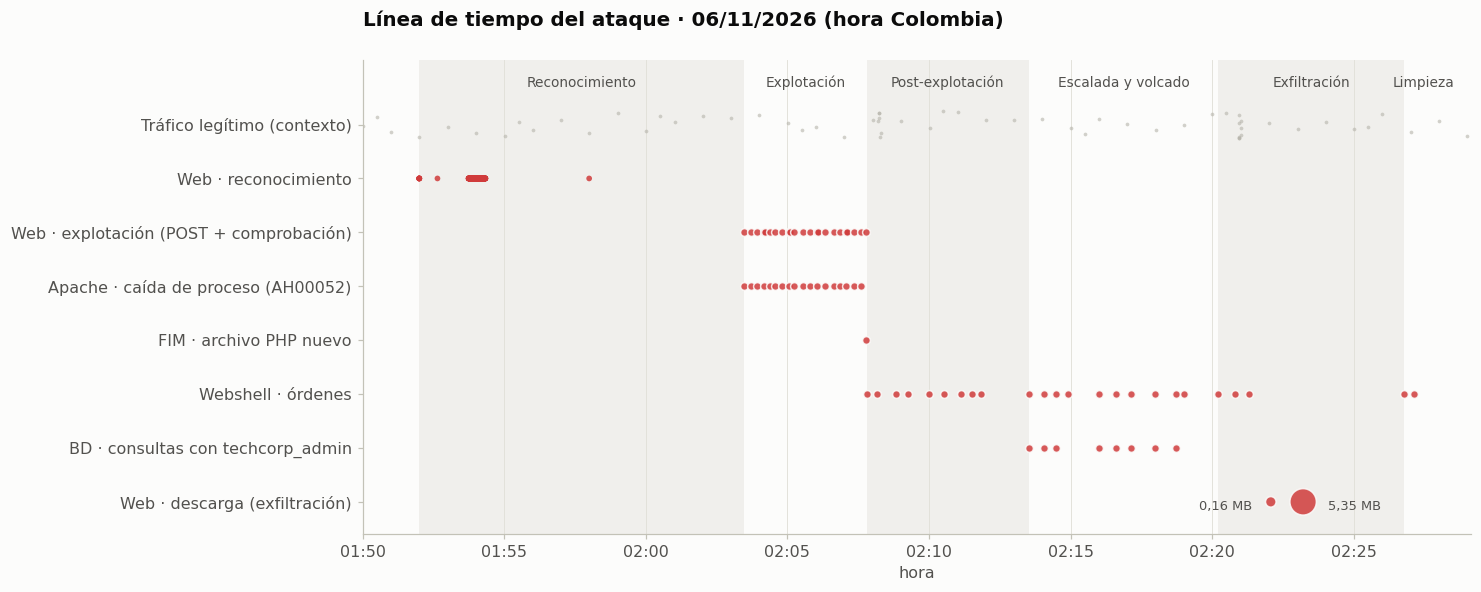

In [25]:
IPS_ATAQUE = sorted(set(ws['client_ip']) | set(posts['client_ip']))
T_INI = pd.Timestamp(con.sql('SELECT MIN(ts) FROM web WHERE client_ip IN (SELECT UNNEST(?::VARCHAR[]))', params=[IPS_ATAQUE]).fetchone()[0])
T_FIN = pd.Timestamp(con.sql('SELECT MAX(ts) FROM web WHERE client_ip IN (SELECT UNNEST(?::VARCHAR[]))', params=[IPS_ATAQUE]).fetchone()[0])

web_atk = con.sql('''
    SELECT ts, client_ip, method, uri, query, status, bytes_sent, bytes_received, user_agent, content_type, request_id
    FROM web WHERE client_ip IN (SELECT UNNEST(?::VARCHAR[])) ORDER BY ts
''', params=[IPS_ATAQUE]).df()

def carril(f):
    if f.uri == WEBSHELL and f.status == 200:
        return 'Web · descarga (exfiltración)' if 'dl=' in (f.query or '') else 'Webshell · órdenes'
    if f.method == 'POST' and (f.content_type or '').startswith('multipart'):
        return 'Web · explotación (POST + comprobación)'
    if f.uri == WEBSHELL:   # comprobaba con GET si la webshell ya existía (404)
        return 'Web · explotación (POST + comprobación)'
    return 'Web · reconocimiento'

web_atk['carril'] = web_atk.apply(carril, axis=1)
eventos = [web_atk[['ts', 'carril', 'bytes_sent']].assign(fuente='web')]
eventos.append(caidas[['ts_caida']].rename(columns={'ts_caida': 'ts'}).assign(carril='Apache · caída de proceso (AH00052)', bytes_sent=0, fuente='app'))
eventos.append(fim_php[['ts']].assign(carril='FIM · archivo PHP nuevo', bytes_sent=0, fuente='fim'))
eventos.append(consultas[consultas['db_user'] == 'techcorp_admin'][['ts']].assign(carril='BD · consultas con techcorp_admin', bytes_sent=0, fuente='db'))
tl = pd.concat(eventos, ignore_index=True).sort_values('ts')

contexto = con.sql('''
    SELECT ts FROM web WHERE ts BETWEEN ? AND ? AND client_ip NOT IN (SELECT UNNEST(?::VARCHAR[]))
''', params=[(T_INI - pd.Timedelta(minutes=5)).to_pydatetime(), (T_FIN + pd.Timedelta(minutes=5)).to_pydatetime(), IPS_ATAQUE]).df()

FASES = {
    'Reconocimiento': T_INI,
    'Explotación': posts['ts'].min(),
    'Post-explotación': primer_200,
    'Escalada y volcado': consultas.loc[consultas['db_user'] == 'techcorp_admin', 'ts'].min(),
    'Exfiltración': ws.loc[ws['orden'].str.startswith('tar'), 'ts'].min(),
    'Limpieza': ws.loc[ws['orden'].str.startswith('rm '), 'ts'].min(),
}
CARRILES = ['Tráfico legítimo (contexto)', 'Web · reconocimiento', 'Web · explotación (POST + comprobación)', 'Apache · caída de proceso (AH00052)',
            'FIM · archivo PHP nuevo', 'Webshell · órdenes', 'BD · consultas con techcorp_admin', 'Web · descarga (exfiltración)']
y = {c: i for i, c in enumerate(reversed(CARRILES))}

fig, ax = plt.subplots(figsize=(13, 5.6))
limites = list(FASES.values()) + [T_FIN + pd.Timedelta(minutes=1)]
for i, (nombre, ini) in enumerate(FASES.items()):
    if i % 2 == 0:
        ax.axvspan(ini, limites[i + 1], color='#f0efec', zorder=0, lw=0)
    ax.text(ini + (limites[i + 1] - ini) / 2, len(CARRILES) - 0.35, nombre, ha='center', va='bottom', fontsize=9, color=TINTA2)
ax.scatter(contexto['ts'], np.full(len(contexto), y['Tráfico legítimo (contexto)']) + np.random.default_rng(0).uniform(-0.25, 0.25, len(contexto)),
           s=6, color=GRIS, alpha=0.6, lw=0, zorder=2)
for c in CARRILES[1:]:
    d = tl[tl['carril'] == c]
    tam = 26 if not c.endswith('(exfiltración)') else 40 + 260 * d['bytes_sent'] / max(1, d['bytes_sent'].max())
    denso = len(d) > 60   # ráfagas (gobuster): sin borde para que se lea como una franja continua
    ax.scatter(d['ts'], np.full(len(d), y[c]), s=tam if not denso else 14, color=CRITICO, alpha=0.85,
               edgecolor='none' if denso else FONDO, linewidth=1, zorder=3)
d = tl[tl['carril'] == 'Web · descarga (exfiltración)']
for i, (_, f) in enumerate(d.iterrows()):
    ax.annotate(mb(f['bytes_sent']), (f['ts'], y['Web · descarga (exfiltración)']), xytext=(-12 if i % 2 == 0 else 16, -3),
                textcoords='offset points', ha='right' if i % 2 == 0 else 'left', va='center', fontsize=8.5, color=TINTA2)
ax.set_yticks(list(y.values()), list(y.keys()))
ax.set_ylim(-0.6, len(CARRILES) + 0.2)
ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax.set_xlim(T_INI - pd.Timedelta(minutes=2), T_FIN + pd.Timedelta(minutes=2))
ax.set_title(f"Línea de tiempo del ataque · {T_INI:%d/%m/%Y} (hora Colombia)", pad=22)
ax.set_xlabel('hora')
guardar(fig, 'fig06_linea_tiempo_ataque')

In [26]:
def hito(ts, fuente, descripcion):
    return {'hora': ts, 'fuente': fuente, 'evento': descripcion}

recon = web_atk[web_atk['carril'] == 'Web · reconocimiento']
gob = recon[recon['user_agent'].str.startswith('gobuster')]
hitos = [
    hito(T_INI, 'web', f"Primer acceso de {web_atk.iloc[0]['client_ip']} con navegador ({web_atk.iloc[0]['user_agent'][:40]}…)"),
    hito(gob['ts'].min(), 'web', f"Enumeración de rutas con gobuster: {len(gob)} peticiones ({(gob['status'] == 404).sum()} 404) en {(gob['ts'].max() - gob['ts'].min()).total_seconds():.0f} s"),
    hito(posts['ts'].min(), 'web', f"Inicia la ráfaga de POST multipart a /login.php ({len(posts)} en total, {(posts['status'] == 500).sum()} con error 500)"),
    hito(caidas['ts_caida'].min(), 'app', f"Primera caída de proceso de Apache (Segmentation fault); {len(caidas)} en total"),
    hito(ultimo_post.ts, 'web', 'POST explotador exitoso (respuesta sin error)'),
    hito(T_IMPLANTE, 'fim', f'Se crea {fim_php.iloc[0]["path"]}'),
    hito(primer_200, 'web', 'Primer uso de la webshell'),
]
for _, f in ws[ws['tipo'] != 'acceso'].iterrows():
    hito_txt = ('Descarga ' + f['orden'] + f' ({mb(f["bytes_sent"])}) desde ' + f['client_ip']) if f['tipo'] == 'descarga' else 'Orden: ' + f['orden_segura']
    hitos.append(hito(f['ts'], 'web', hito_txt))
for _, f in consultas[consultas['db_user'] == 'techcorp_admin'].iterrows():
    hitos.append(hito(f['ts'], 'db', f"[{f['db_user']}] {f['sql']} → {f['rows_sent']} filas"))
super_timeline = pd.DataFrame(hitos).sort_values('hora').reset_index(drop=True)
super_timeline.to_csv(SALIDA / 'super_timeline.csv', index=False)
pd.set_option('display.max_colwidth', 140)
display(super_timeline.style.hide(axis='index'))

hora,fuente,evento
2026-11-06 01:52:00,web,Primer acceso de 203.0.113.66 con navegador (Mozilla/5.0 (X11; Linux x86_64; rv:128.0…)
2026-11-06 01:53:44.571000,web,Enumeración de rutas con gobuster: 384 peticiones (354 404) en 36 s
2026-11-06 02:03:28.986000,web,"Inicia la ráfaga de POST multipart a /login.php (19 en total, 18 con error 500)"
2026-11-06 02:03:28.986000,app,Primera caída de proceso de Apache (Segmentation fault); 18 en total
2026-11-06 02:07:46.545000,web,POST explotador exitoso (respuesta sin error)
2026-11-06 02:07:46.545000,fim,Se crea /var/www/html/uploads/avatars/thumb_8f3a.php
2026-11-06 02:07:48.685000,web,Primer uso de la webshell
2026-11-06 02:08:10.606000,web,Orden: id
2026-11-06 02:08:49.224000,web,Orden: whoami
2026-11-06 02:09:15.731000,web,Orden: uname -a


## 10. Conclusiones: respuestas a las preguntas forenses

In [27]:
n_cli = int(resumen_exp.loc[resumen_exp['tabla'] == 'clientes', 'registros'].sum())
n_emp = int(resumen_exp.loc[resumen_exp['tabla'] == 'empleados', 'registros'].sum())
permanencia = T_FIN - T_INI
ip_origen = posts['client_ip'].mode()[0]
ips_exfil = ', '.join(sorted(descargas['client_ip'].unique()))

display(Markdown(f'''
| Pregunta | Respuesta (evidencia) |
|---|---|
| **¿Cuándo?** | Del **{T_INI:%d/%m/%Y %H:%M:%S}** al **{T_FIN:%H:%M:%S}** (hora Colombia): **{permanencia.total_seconds() / 60:.0f} minutos** de actividad. Explotación exitosa: **{T_IMPLANTE:%H:%M:%S}**. Exfiltración: **{descargas["ts"].min():%H:%M:%S}–{descargas["ts"].max():%H:%M:%S}**. |
| **¿Dónde?** | Servidor **web-01** (portal interno, PHP 8.3.30 + Apache). Punto de entrada: **`/login.php`** (público, sin autenticación). Artefacto: **`{fim_php.iloc[0]["path"]}`**. Base de datos **db-01**, esquema `techcorp`. |
| **¿Cómo?** | **{len(posts)} POST multipart** con el campo `PHP_SESSION_UPLOAD_PROGRESS` y cuerpos de hasta {num(posts["bytes_received"].max() / 1024)} KB: el patrón de **PHP2Shell (CVE-2026-109618)**. Hubo {len(caidas)} caídas de proceso antes de lograr la **webshell**. Desde ella leyó `config/database.php`, obtuvo la cuenta **`techcorp_admin`** (escalada), volcó las tablas a `/tmp/.d`, las comprimió y las descargó. |
| **¿Quién / desde dónde?** | IP de origen **{ip_origen}** (reconocimiento con `gobuster/3.6`, explotación con `python-requests`). Exfiltración desde **{ips_exfil}** (`curl/8.5.0`). Ambas son externas y no figuran en el inventario ni en el registro de cambios. |
| **¿Qué registros?** | **{num(n_cli)} clientes** (todos: documento, contacto, saldo y cupo) y **{num(n_emp)} empleados** (incluidos **salario** y **hash de contraseña**). Se extrajeron **{mb(BYTES_EXFIL)}**: los volcados y una copia del código fuente del portal con las fotos de perfil. |
'''))


| Pregunta | Respuesta (evidencia) |
|---|---|
| **¿Cuándo?** | Del **06/11/2026 01:52:00** al **02:27:08** (hora Colombia): **35 minutos** de actividad. Explotación exitosa: **02:07:46**. Exfiltración: **02:22:04–02:23:12**. |
| **¿Dónde?** | Servidor **web-01** (portal interno, PHP 8.3.30 + Apache). Punto de entrada: **`/login.php`** (público, sin autenticación). Artefacto: **`/var/www/html/uploads/avatars/thumb_8f3a.php`**. Base de datos **db-01**, esquema `techcorp`. |
| **¿Cómo?** | **19 POST multipart** con el campo `PHP_SESSION_UPLOAD_PROGRESS` y cuerpos de hasta 854 KB: el patrón de **PHP2Shell (CVE-2026-109618)**. Hubo 18 caídas de proceso antes de lograr la **webshell**. Desde ella leyó `config/database.php`, obtuvo la cuenta **`techcorp_admin`** (escalada), volcó las tablas a `/tmp/.d`, las comprimió y las descargó. |
| **¿Quién / desde dónde?** | IP de origen **203.0.113.66** (reconocimiento con `gobuster/3.6`, explotación con `python-requests`). Exfiltración desde **203.0.113.67** (`curl/8.5.0`). Ambas son externas y no figuran en el inventario ni en el registro de cambios. |
| **¿Qué registros?** | **2.000 clientes** (todos: documento, contacto, saldo y cupo) y **500 empleados** (incluidos **salario** y **hash de contraseña**). Se extrajeron **5,50 MB**: los volcados y una copia del código fuente del portal con las fotos de perfil. |


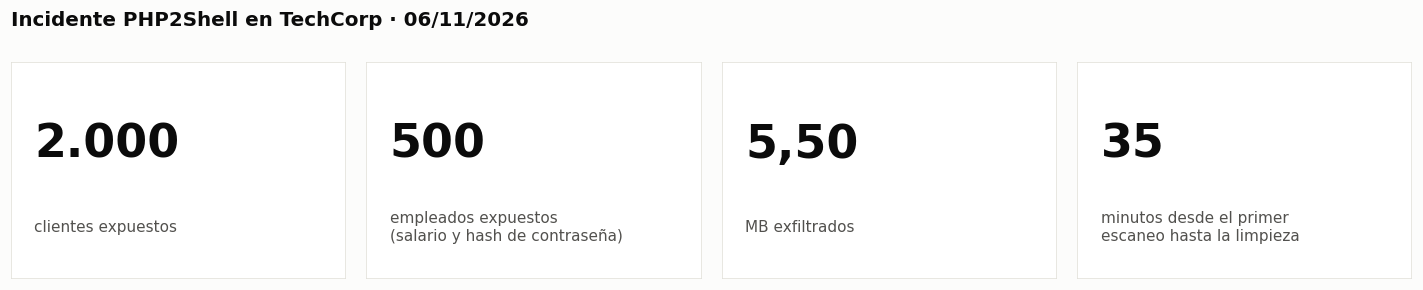

In [28]:
# Figura resumen para la diapositiva de cierre (cifras clave)
cifras = [(num(n_cli), 'clientes expuestos'), (num(n_emp), 'empleados expuestos\n(salario y hash de contraseña)'),
          (mb(BYTES_EXFIL).replace(' MB', ''), 'MB exfiltrados'), (f'{permanencia.total_seconds() / 60:.0f}', 'minutos desde el primer\nescaneo hasta la limpieza')]
fig, axs = plt.subplots(1, 4, figsize=(13, 2.6))
fig.subplots_adjust(left=0.01, right=0.99, top=0.80, bottom=0.04, wspace=0.06)
for ax, (valor, etiqueta) in zip(axs, cifras):
    ax.axis('off')
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, facecolor='#ffffff', edgecolor=REJILLA, lw=1))
    ax.text(0.07, 0.62, valor, fontsize=30, fontweight='semibold', color=TINTA, transform=ax.transAxes, va='center')
    ax.text(0.07, 0.24, etiqueta, fontsize=10, color=TINTA2, transform=ax.transAxes, va='center')
fig.suptitle(f'Incidente PHP2Shell en TechCorp · {T_INI:%d/%m/%Y}', x=0.01, ha='left', fontsize=13, fontweight='semibold')
guardar(fig, 'fig07_cifras_clave')

In [29]:
# Indicadores de compromiso (IOC) para bloquear y buscar en otros sistemas
iocs = {
    'ips': [{'ip': ip, 'rol': 'reconocimiento y explotación' if ip == ip_origen else 'exfiltración'} for ip in IPS_ATAQUE],
    'user_agents': sorted(web_atk['user_agent'].unique()),
    'archivos': [{'ruta': fim_php.iloc[0]['path'], 'sha256': fim_php.iloc[0]['sha256'], 'tipo': 'webshell'},
                 {'ruta': '/tmp/.d/, /tmp/.d.tgz, /tmp/.w.tgz', 'tipo': 'preparación y empaquetado (borrados por el atacante)'}],
    'uris': [WEBSHELL, '/login.php (POST multipart con PHP_SESSION_UPLOAD_PROGRESS)'],
    'cuentas_comprometidas': ['techcorp_admin (BD)', 'techcorp_app (BD, contraseña expuesta en config)', f'{n_emp} cuentas del portal (hash bcrypt filtrado)'],
    'vulnerabilidad': 'PHP 8.3.30 < 8.3.36: PHP2Shell (CVE-2026-109618 / CVE-2026-109619)',
}
(SALIDA / 'iocs.json').write_text(json.dumps(iocs, ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(iocs, ensure_ascii=False, indent=2))

{
  "ips": [
    {
      "ip": "203.0.113.66",
      "rol": "reconocimiento y explotación"
    },
    {
      "ip": "203.0.113.67",
      "rol": "exfiltración"
    }
  ],
  "user_agents": [
    "Mozilla/5.0 (X11; Linux x86_64; rv:128.0) Gecko/20100101 Firefox/128.0",
    "curl/8.5.0",
    "gobuster/3.6",
    "python-requests/2.32.3"
  ],
  "archivos": [
    {
      "ruta": "/var/www/html/uploads/avatars/thumb_8f3a.php",
      "sha256": "a0a401e8e0260ef38cb542a3c867cb717d66b364bdecb99cc81182522e153c1e",
      "tipo": "webshell"
    },
    {
      "ruta": "/tmp/.d/, /tmp/.d.tgz, /tmp/.w.tgz",
      "tipo": "preparación y empaquetado (borrados por el atacante)"
    }
  ],
  "uris": [
    "/uploads/avatars/thumb_8f3a.php",
    "/login.php (POST multipart con PHP_SESSION_UPLOAD_PROGRESS)"
  ],
  "cuentas_comprometidas": [
    "techcorp_admin (BD)",
    "techcorp_app (BD, contraseña expuesta en config)",
    "500 cuentas del portal (hash bcrypt filtrado)"
  ],
  "vulnerabilidad": "PHP 8.3.30

### Recomendaciones

**Contención inmediata**
1. Aislar `web-01`, conservar una imagen del disco y la memoria, y eliminar la webshell solo después de preservarla.
2. Bloquear 203.0.113.66 y 203.0.113.67 (y vigilar el bloque 203.0.113.0/24).
3. Rotar **todas** las credenciales: `techcorp_admin`, `techcorp_app` y las contraseñas de los 500 empleados, porque sus hashes se filtraron.

**Erradicación y recuperación**
4. Actualizar PHP a **8.3.36 o superior** (corrige CVE-2026-109618/109619) y reconstruir el servidor desde una imagen limpia.
5. Prohibir la ejecución de PHP en `/uploads`, desactivar `expose_php` y, si no se usa, `session.upload_progress.enabled`.
6. Sacar las credenciales del docroot (gestor de secretos) y retirar la cuenta de mantenimiento con todos los privilegios.

**Detección y gobierno**
7. Llevar los cuatro logs a un SIEM con alertas para: ráfagas de 5xx, POST multipart a endpoints que no reciben archivos, archivos `.php` nuevos (FIM) y uso de cuentas de BD fuera de lo habitual.
8. Controlar el tráfico de salida y el volumen por sesión (respuestas > p99,9).
9. **Ley 1581 de 2012 (habeas data):** reportar el incidente a la **SIC** (Registro Nacional de Bases de Datos) y notificar a los titulares afectados con los listados generados en `salida/`.

## 11. Cierre: integridad de la evidencia y validación

In [30]:
verif = custodia[['archivo', 'sha256']].copy()
verif['sha256_final'] = [sha256(EVIDENCIA / a) for a in verif['archivo']]
verif['intacto'] = verif['sha256'] == verif['sha256_final']
display(verif[['archivo', 'intacto']])
print('✔ La evidencia no cambió durante el análisis.' if verif['intacto'].all() else '✖ ¡ATENCIÓN! Algún archivo cambió.')

,archivo,intacto
0,app/app.jsonl,True
1,db/audit.jsonl,True
2,fim/fim.jsonl,True
3,web/access.jsonl,True


✔ La evidencia no cambió durante el análisis.


In [31]:
# Solo para el docente: compara las conclusiones con lo que el generador realmente inyectó
ruta_sol = SOLUCIONARIO / 'solucionario_incidente.json' if SOLUCIONARIO else None
if ruta_sol and ruta_sol.exists():
    sol = json.loads(ruta_sol.read_text(encoding='utf-8'))
    ini_real = pd.Timestamp(sol['fases']['1_reconocimiento']['inicio_local']).tz_localize(None)
    fin_real = pd.Timestamp(sol['fin_local']).tz_localize(None)
    checks = pd.DataFrame([
        ('IP de origen', ip_origen, sol['ip_origen']),
        ('IP de exfiltración', ips_exfil, sol['ip_exfiltracion']),
        ('Webshell', WEBSHELL, sol['webshell']),
        ('Cuenta de BD usada', 'techcorp_admin' if (consultas['db_user'] == 'techcorp_admin').any() else '-', sol['cuenta_bd_usada']),
        ('Intentos de explotación', len(posts), sol['intentos_explotacion']),
        ('Bytes exfiltrados (±1 %: el log de Apache incluye cabeceras)', BYTES_EXFIL, sol['bytes_exfiltrados']),
        ('Inicio (±1 s)', f'{T_INI:%H:%M:%S}', f'{ini_real:%H:%M:%S}'),
        ('Fin (±1 s)', f'{T_FIN:%H:%M:%S}', f'{fin_real:%H:%M:%S}'),
    ], columns=['dato', 'análisis', 'solucionario'])
    checks['¿coincide?'] = [str(a) == str(b) or (isinstance(a, int) and abs(a - b) <= max(1, 0.01 * b)) for a, b in zip(checks['análisis'], checks['solucionario'])]
    checks.loc[checks['dato'].str.startswith(('Inicio', 'Fin')), '¿coincide?'] = [abs((T_INI - ini_real).total_seconds()) <= 1, abs((T_FIN - fin_real).total_seconds()) <= 1]
    display(checks.style.hide(axis='index'))
else:
    print('No hay solucionario montado (es opcional).')

dato,análisis,solucionario,¿coincide?
IP de origen,203.0.113.66,203.0.113.66,True
IP de exfiltración,203.0.113.67,203.0.113.67,True
Webshell,/uploads/avatars/thumb_8f3a.php,/uploads/avatars/thumb_8f3a.php,True
Cuenta de BD usada,techcorp_admin,techcorp_admin,True
Intentos de explotación,19,19,True
Bytes exfiltrados (±1 %: el log de Apache incluye cabeceras),5771198,5770626,True
Inicio (±1 s),01:52:00,01:52:00,True
Fin (±1 s),02:27:08,02:27:08,True
